# Initial Data Exploration

This notebook explores the earthquake damage prediction dataset to understand its structure, data quality and key characteristics before model development.

Objectives
- Understand the dataset structure.
- Check for missing values and unusual values.
- Explore the distribution of damage grades.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading

In [16]:
data = pd.read_csv('../data/raw/train_values.csv')
target = pd.read_csv('../data/raw/train_labels.csv')
test_value = pd.read_csv('../data/raw/test_values.csv')

data.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


In [17]:
target.head()

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [18]:
test_value.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,300051,17,596,11307,3,20,7,6,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,99355,6,141,11987,2,25,13,5,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,1,1,0,0,0,0,0,0,0,0,0
2,890251,22,19,10044,2,5,4,5,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,745817,26,39,633,1,0,19,3,t,r,x,v,j,t,d,0,0,0,0,0,1,0,0,0,0,0,v,2,1,0,0,1,0,0,0,0,0,0,0
4,421793,17,289,7970,3,15,8,7,t,r,q,f,q,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


In [19]:
# Show all columns
pd.set_option('display.max_columns', None)

In [20]:
# Merge data and target into one DataFrame

df = pd.merge(data, target, on=['building_id'])
df.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


## EDA

### Basic Data Exploration

In [21]:
df.shape

(260601, 40)

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             260601 non-null  int64
 1   geo_level_1_id                          260601 non-null  int64
 2   geo_level_2_id                          260601 non-null  int64
 3   geo_level_3_id                          260601 non-null  int64
 4   count_floors_pre_eq                     260601 non-null  int64
 5   age                                     260601 non-null  int64
 6   area_percentage                         260601 non-null  int64
 7   height_percentage                       260601 non-null  int64
 8   land_surface_condition                  260601 non-null  str  
 9   foundation_type                         260601 non-null  str  
 10  roof_type                               260601 non-null  str  
 11  ground_floo

In [23]:
# Class distribution of the target 'damage_grade'
df.groupby('damage_grade').size().reset_index()

,damage_grade,0
0,1,25124
1,2,148259
2,3,87218


In [24]:
df.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
count,2.606010e+05,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000
mean,5.256755e+05,13.900353,701.074685,6257.876148,2.129723,26.535029,8.018051,5.434365,0.088645,0.761935,0.034332,0.018235,0.068154,0.075268,0.254988,0.085011,0.042590,0.015859,0.014985,0.983949,0.111880,0.064378,0.033626,0.008101,0.000940,0.000361,0.001071,0.000188,0.000146,0.000088,0.005119,2.238272
std,3.045450e+05,8.033617,412.710734,3646.369645,0.727665,73.565937,4.392231,1.918418,0.284231,0.425900,0.182081,0.133800,0.252010,0.263824,0.435855,0.278899,0.201931,0.124932,0.121491,0.418389,0.315219,0.245426,0.180265,0.089638,0.030647,0.018989,0.032703,0.013711,0.012075,0.009394,0.071364,0.611814
min,4.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.611900e+05,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,5.257570e+05,12.000000,702.000000,6270.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,7.897620e+05,21.000000,1050.000000,9412.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,1.052934e+06,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [25]:
# Categorical data description
df.describe(include=['O'])

C:\Users\mrwho\AppData\Local\Temp\ipykernel_23124\4206751175.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['O'])


,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,legal_ownership_status
count,260601,260601,260601,260601,260601,260601,260601,260601
unique,3,5,3,5,4,4,10,4
top,t,r,n,f,q,s,d,v
freq,216757,219196,182842,209619,165282,202090,250072,250939


In [26]:
df.columns

Index(['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id',
       'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage',
       'land_surface_condition', 'foundation_type', 'roof_type',
       'ground_floor_type', 'other_floor_type', 'position',
       'plan_configuration', 'has_superstructure_adobe_mud',
       'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag',
       'has_superstructure_cement_mortar_stone',
       'has_superstructure_mud_mortar_brick',
       'has_superstructure_cement_mortar_brick', 'has_superstructure_timber',
       'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered',
       'has_superstructure_rc_engineered', 'has_superstructure_other',
       'legal_ownership_status', 'count_families', 'has_secondary_use',
       'has_secondary_use_agriculture', 'has_secondary_use_hotel',
       'has_secondary_use_rental', 'has_secondary_use_institution',
       'has_secondary_use_school', 'has_secondary_use_i

#### Note📒

Based on the data description from [DrivenData](https://www.drivendata.org/competitions/57/nepal-earthquake/page/136/) and the Kaggle dataset ["Earthquake Magnitude, Damage and Impact"](https://www.kaggle.com/datasets/arashnic/earthquake-magnitude-damage-and-impact), I attempted to recover the original category names from the random lowercase ASCII characters in the raw data. This helps me analyse their relationships with building damage grades.  

The features are categorised by data types as follows:  
geographic ID - 🌍, numerical(integer) - 🔢, categorical - 🧺, binary - ⚖️  

---
- **Geographic region ID** 🌍  
`geo_level_1_id` - *district*,  `geo_level_2_id` - *vdcmun*,  `geo_level_3_id` - *ward*   
The intensity of earthquakes varies in different locations. (Note: Although the data is integer, it is essentially a categorical data)

- **Number of floors before the earthquake** 🔢  
`count_floors_pre_eq` - Might be positively correlated with the degree of damage.  

- **Age of the building in years** 🔢  
`age`  - The older the building, the more likely it is to be damaged in the earthquake.  

- **Normalised building size** 🔢  
`area_percentage`   - Might be nagatively correlated with the target.  
`height_percentage` - Might be positively correlated with the damage grade, and might be highly correlated with `count_floors_pre_eq`.  

- **Surface condition of the land where the building was built** 🧺  
`land_surface_condition` - *['Flat', 'Moderate slope', 'Steep slope']*  
The slope of the building's location might be related to the building's earthquake-resistant capacity.  

- **Building structure (material) type** 🧺  
`foundation_type` - *['Other', 'Mud mortar-Stone/Brick', 'Cement-Stone/Brick', 'Bamboo/Timber', 'RC']*  
`roof_type` - *['Bamboo/Timber-Light roof', 'Bamboo/Timber-Heavy roof', 'RCC/RB/RBC']*  
`ground_floor_type` - *['Mud', 'Brick/Stone', 'RC', 'Timber', 'Other']*  
`other_floor_type` - *['Not applicable', 'TImber/Bamboo-Mud', 'Timber-Planck', 'RCC/RB/RBC']*  
Building material affects earthquake resistance.  

- **Position (attached type)** 🧺  
`position` - *['Not attached', 'Attached-1 side', 'Attached-2 side', 'Attached-3 side']*  
How a building is connected to others might be related to its stability.

- **Building plan configuration** 🧺  
`plan_configuration` - *['Rectangular', 'L-shape', 'Square', 'T-shape', 'Multi-projected', 'H-shape', 'U-shape', 'Others', 'E-shape', 'Building with Central Courtyard']*  
Shape complexity might be related to structural stability.  

- **Superstructure building materials**  ⚖️  
`has_superstructure_` [`adobe_mud`, `mud_mortar_stone`, `stone_flag`, `cement_mortar_stone`, `mud_mortar_brick`, `cement_mortar_brick`, `timber`, `bamboo`, `rc_non_engineered`, `rc_engineered`, `other`]  
Superstructure materials influence its earthquake resistance.  

- **Legal ownership status of the land** 🧺  
`legal_ownership_status` - *['Private', 'Other', 'Institutional', 'Public']*  
Might be related to the building maintenance level.  

- **Number of families live in the building** 🔢  
`count_families` - Might reflect building crowding pressures.  

- **If the building was used for secondary purpose** ⚖️  
`has_secondary_use_` [`has_secondary_use`, `agriculture`, `hotel`, `rental`, `institution`, `school`, `industry`, `health_post`, `gov_office`, `police`, `other`]  
Might be related to maintenance level.  

---
The obfuscated lowercase ASCII characters could not be matched to the original category names.


#### Feature Exploration

In [27]:
int_col = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

categorical_col = ['land_surface_condition', 'foundation_type', 'roof_type',
       'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

superstructure = ['has_superstructure_adobe_mud',
       'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag',
       'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick',
       'has_superstructure_cement_mortar_brick', 'has_superstructure_timber',
       'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered',
       'has_superstructure_rc_engineered', 'has_superstructure_other']

secondary_use_col = ['has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel',
       'has_secondary_use_rental', 'has_secondary_use_institution',
       'has_secondary_use_school', 'has_secondary_use_industry',
       'has_secondary_use_health_post', 'has_secondary_use_gov_office',
       'has_secondary_use_use_police', 'has_secondary_use_other']

binary_col = superstructure + secondary_use_col

id_col = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']

In [28]:
# Missing data
df.isnull().sum()

building_id                               0
geo_level_1_id                            0
geo_level_2_id                            0
geo_level_3_id                            0
count_floors_pre_eq                       0
age                                       0
area_percentage                           0
height_percentage                         0
land_surface_condition                    0
foundation_type                           0
roof_type                                 0
ground_floor_type                         0
other_floor_type                          0
position                                  0
plan_configuration                        0
has_superstructure_adobe_mud              0
has_superstructure_mud_mortar_stone       0
has_superstructure_stone_flag             0
has_superstructure_cement_mortar_stone    0
has_superstructure_mud_mortar_brick       0
has_superstructure_cement_mortar_brick    0
has_superstructure_timber                 0
has_superstructure_bamboo       

In [29]:
# Duplicated data
df[df.duplicated(keep=False)]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade


##### Exploration of Binary Features

**Check if `has_secondary_use` column is redundant.**  
Whether `has_secondary_use` is equal to the logical OR of all other secondary-use features:

In [30]:
# Check for rows where 'has_secondary_use' is 1 but all other secondary-use features are 0
df.loc[(df['has_secondary_use'] == 1) & ((df[secondary_use_col].drop(['has_secondary_use'], axis=1).sum(axis=1)) == 0)]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade


In [31]:
# Check for rows where 'has_secondary_use' is 1 but none of the other secondary-use features are 0
df.loc[(df['has_secondary_use'] == 0) & ((df[secondary_use_col].drop(['has_secondary_use'], axis=1).sum(axis=1)) != 0)]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade


The result shows that `has_secondary_use` is redundant and will be dropped.

In [32]:
# Check for rows where more than one secondary-use features (other than 'has_secondary_use') are set to 1
df.loc[(df[secondary_use_col].drop(['has_secondary_use'], axis=1).sum(axis=1)) >= 2, secondary_use_col]

,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
304,1,1,0,0,0,0,0,0,0,0,1
1408,1,1,0,0,0,0,0,0,0,0,1
1593,1,1,0,0,0,0,0,0,0,0,1
2329,1,1,0,0,0,0,0,0,0,0,1
3704,1,0,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
256746,1,1,0,0,0,0,0,0,0,0,1
257939,1,1,0,0,0,0,0,0,0,0,1
258184,1,1,0,0,0,0,0,0,0,0,1
258755,1,1,0,0,0,0,0,0,0,0,1


In [33]:
# Check again after dropping 'has_secondary_use_other'
df.loc[(df[secondary_use_col].drop(['has_secondary_use','has_secondary_use_other'], axis=1).sum(axis=1)) >= 2]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade


It shows that after dropping `has_secondary_use`, all secondary-use features are mutually exclusive, except for `has_secondary_use_other`.

In [34]:
# Check for rows that have no flagged superstructure indicator
df.loc[df[superstructure].sum(axis=1)==0]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade


In [35]:
# Check if superstructure features are exclusive other than 'has_superstructure_other'
df.loc[df[superstructure].drop(['has_superstructure_other'], axis=1).sum(axis=1)>=2]

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
7,475515,20,323,12236,2,0,8,6,t,w,q,v,x,s,u,0,0,0,0,0,1,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,1
8,441126,0,757,7219,2,15,8,6,t,r,q,f,q,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
10,7962,17,1119,12188,2,20,9,6,t,r,q,f,q,t,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260583,192421,7,322,2843,2,10,6,6,t,r,n,f,q,s,d,1,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
260585,722577,6,744,10556,2,45,17,5,t,r,n,f,x,t,d,0,1,0,0,0,0,1,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
260587,603159,8,696,4513,3,20,7,9,t,r,n,f,q,s,d,0,1,0,0,0,0,1,0,0,0,0,v,1,1,1,0,0,0,0,0,0,0,0,0,3
260590,695987,20,922,10283,2,5,7,5,t,r,n,f,q,s,d,0,0,1,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2


It shows that superstructure features are not exclusive.

#### Statistical Analysis

In [36]:
# Distribution of categories in the categorical features
for col in categorical_col + ['geo_level_1_id']:
    display(df[col].value_counts().reset_index())

,land_surface_condition,count
0,t,216757
1,n,35528
2,o,8316


,foundation_type,count
0,r,219196
1,w,15118
2,u,14260
3,i,10579
4,h,1448


,roof_type,count
0,n,182842
1,q,61576
2,x,16183


,ground_floor_type,count
0,f,209619
1,x,24877
2,v,24593
3,z,1004
4,m,508


,other_floor_type,count
0,q,165282
1,x,43448
2,j,39843
3,s,12028


,position,count
0,s,202090
1,t,42896
2,j,13282
3,o,2333


,plan_configuration,count
0,d,250072
1,q,5692
2,u,3649
3,s,346
4,c,325
5,a,252
6,o,159
7,m,46
8,n,38
9,f,22


,legal_ownership_status,count
0,v,250939
1,a,5512
2,w,2677
3,r,1473


,geo_level_1_id,count
0,6,24381
1,26,22615
2,10,22079
3,17,21813
4,8,19080
5,7,18994
6,20,17216
7,21,14889
8,4,14568
9,27,12532


##### Proportions of Each `damage_grade`  in Each Category

In [37]:
for col in categorical_col:
    display(df.groupby([col, 'damage_grade']).size().div(df.groupby([col])['damage_grade'].size(), axis=0).unstack())

damage_grade,1,2,3
land_surface_condition,,,
n,0.071943,0.604706,0.323351
o,0.072391,0.566138,0.361472
t,0.101339,0.563151,0.335509


damage_grade,1,2,3
foundation_type,,,
h,0.247238,0.399862,0.352901
i,0.567539,0.411570,0.020890
r,0.048906,0.572615,0.378479
u,0.258696,0.598948,0.142356
w,0.287935,0.613176,0.098889


damage_grade,1,2,3
roof_type,,,
n,0.074091,0.582180,0.343728
q,0.063759,0.552309,0.383932
x,0.472780,0.482173,0.045047


damage_grade,1,2,3
ground_floor_type,,,
f,0.059508,0.571880,0.368612
m,0.177165,0.675197,0.147638
v,0.419184,0.527427,0.053389
x,0.082486,0.584315,0.333199
z,0.198207,0.529880,0.271912


damage_grade,1,2,3
other_floor_type,,,
j,0.223025,0.511056,0.265919
q,0.044693,0.594862,0.360445
s,0.450865,0.490855,0.058281
x,0.078899,0.544858,0.376243


damage_grade,1,2,3
position,,,
j,0.126111,0.594715,0.279175
o,0.051436,0.689670,0.258894
s,0.098308,0.574254,0.327438
t,0.080707,0.529187,0.390106


damage_grade,1,2,3
plan_configuration,,,
a,0.261905,0.623016,0.115079
c,0.264615,0.633846,0.101538
d,0.093213,0.569928,0.336859
f,NaN,0.727273,0.272727
m,0.173913,0.739130,0.086957
n,0.157895,0.526316,0.315789
o,0.251572,0.603774,0.144654
q,0.137210,0.454146,0.408644
s,0.153179,0.644509,0.202312


damage_grade,1,2,3
legal_ownership_status,,,
a,0.274129,0.557692,0.168179
r,0.144603,0.493551,0.361847
v,0.092732,0.570473,0.336795
w,0.048562,0.487112,0.464326


In [38]:
for col in binary_col:
    display(df.groupby([col, 'damage_grade']).size().div(df.groupby([col])['damage_grade'].size(), axis=0).unstack())

damage_grade,1,2,3
has_superstructure_adobe_mud,,,
0,0.103284,0.565714,0.331002
1,0.025713,0.601792,0.372495


damage_grade,1,2,3
has_superstructure_mud_mortar_stone,,,
0,0.263765,0.553063,0.183172
1,0.044117,0.573864,0.382019


damage_grade,1,2,3
has_superstructure_stone_flag,,,
0,0.099112,0.571121,0.329766
1,0.020342,0.506762,0.472896


damage_grade,1,2,3
has_superstructure_cement_mortar_stone,,,
0,0.094958,0.566784,0.338258
1,0.174453,0.683502,0.142045


damage_grade,1,2,3
has_superstructure_mud_mortar_brick,,,
0,0.100894,0.562350,0.336757
1,0.035077,0.658634,0.306289


...

damage_grade,1,2,3
has_secondary_use_industry,,,
0,0.096285,0.568938,0.334778
1,0.211470,0.544803,0.243728


damage_grade,1,2,3
has_secondary_use_health_post,,,
0,0.096380,0.568896,0.334724
1,0.244898,0.653061,0.102041


damage_grade,1,2,3
has_secondary_use_gov_office,,,
0,0.096372,0.568914,0.334714
1,0.342105,0.552632,0.105263


damage_grade,1,2,3
has_secondary_use_use_police,,,
0,0.096401,0.568916,0.334683
1,0.173913,0.521739,0.304348


damage_grade,1,2,3
has_secondary_use_other,,,
0,0.096229,0.568553,0.335218
1,0.131184,0.638681,0.230135


##### Mean Values of the Numerical Features for Each `damage_grade`

In [39]:
for col in binary_col:
    display(df.groupby(['damage_grade'])[col].mean().reset_index())

,damage_grade,has_superstructure_adobe_mud
0,1,0.023643
1,2,0.093768
2,3,0.098661


,damage_grade,has_superstructure_mud_mortar_stone
0,1,0.348671
1,2,0.768567
2,3,0.869706


,damage_grade,has_superstructure_stone_flag
0,1,0.007244
1,2,0.030582
2,3,0.048511


,damage_grade,has_superstructure_cement_mortar_stone
0,1,0.032996
1,2,0.021908
2,3,0.007739


,damage_grade,has_superstructure_mud_mortar_brick
0,1,0.024797
1,2,0.078902
2,3,0.062372


...

,damage_grade,has_secondary_use_industry
0,1,0.002348
1,2,0.001025
2,3,0.000780


,damage_grade,has_secondary_use_health_post
0,1,0.000478
1,2,0.000216
2,3,0.000057


,damage_grade,has_secondary_use_gov_office
0,1,0.000517
1,2,0.000142
2,3,0.000046


,damage_grade,has_secondary_use_use_police
0,1,0.000159
1,2,0.000081
2,3,0.000080


,damage_grade,has_secondary_use_other
0,1,0.006965
1,2,0.005747
2,3,0.003520


In [40]:
for col in int_col:
    display(df.groupby('damage_grade')[col].mean().reset_index())

,damage_grade,count_floors_pre_eq
0,1,1.841307
1,2,2.131763
2,3,2.209338


,damage_grade,age
0,1,17.320490
1,2,27.342118
2,3,27.817423


,damage_grade,area_percentage
0,1,9.716009
1,2,8.034049
2,3,7.501743


,damage_grade,height_percentage
0,1,5.147349
1,2,5.432345
2,3,5.520477


,damage_grade,count_families
0,1,0.915101
1,2,0.982018
2,3,1.007063


##### Medians of the Numerical Features for Each `damage_grade`

In [41]:
for col in int_col:
    display(df.groupby('damage_grade')[col].median().reset_index())

,damage_grade,count_floors_pre_eq
0,1,2.0
1,2,2.0
2,3,2.0


,damage_grade,age
0,1,5.0
1,2,15.0
2,3,20.0


,damage_grade,area_percentage
0,1,8.0
1,2,7.0
2,3,7.0


,damage_grade,height_percentage
0,1,5.0
1,2,5.0
2,3,5.0


,damage_grade,count_families
0,1,1.0
1,2,1.0
2,3,1.0


### Visualisation

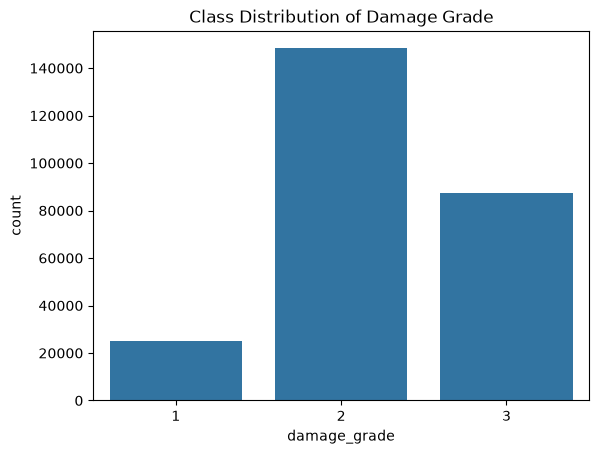

In [42]:
# Class distribution of the target

sns.countplot(x='damage_grade', data=df)
plt.title('Class Distribution of Damage Grade')
# plt.savefig('plots/damage_grade_countplot.png')
plt.show()

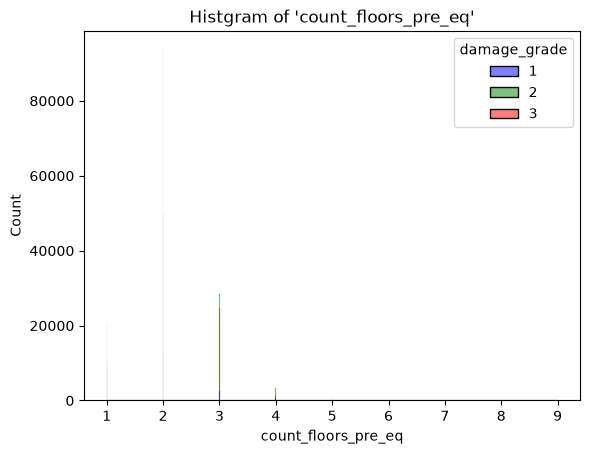

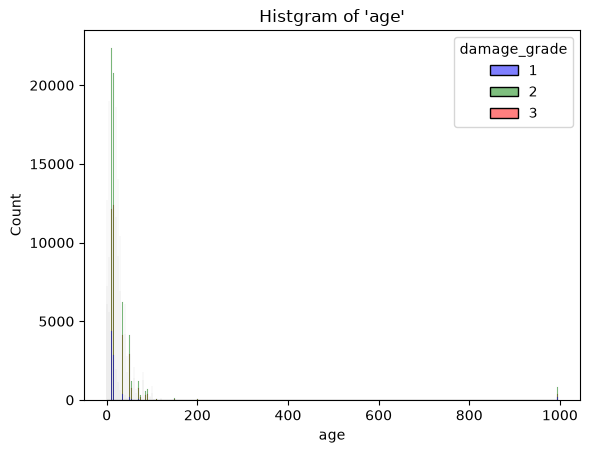

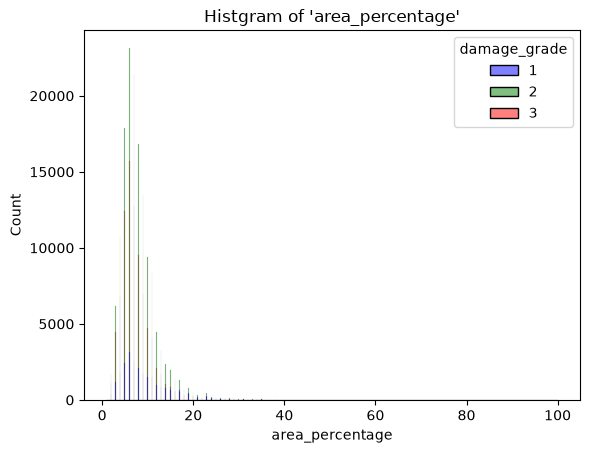

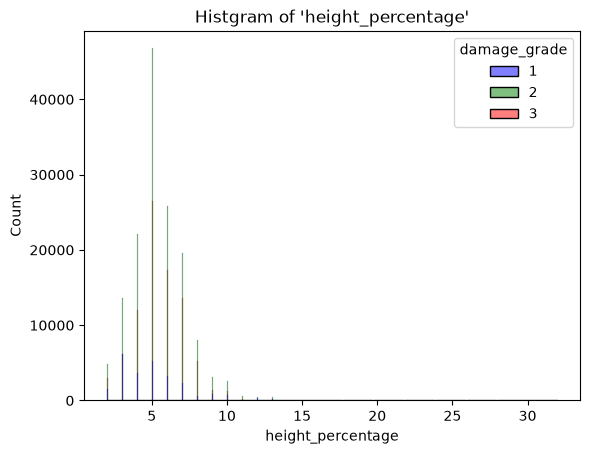

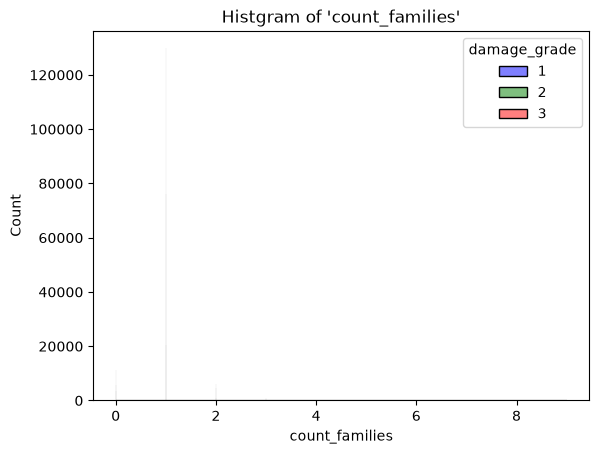

In [43]:
# Histgram

for col in int_col:
    sns.histplot(data=df, x=col, hue='damage_grade', palette=['blue', 'green', 'red'])
    plt.title(f"Histgram of '{col}'")
    plt.show()

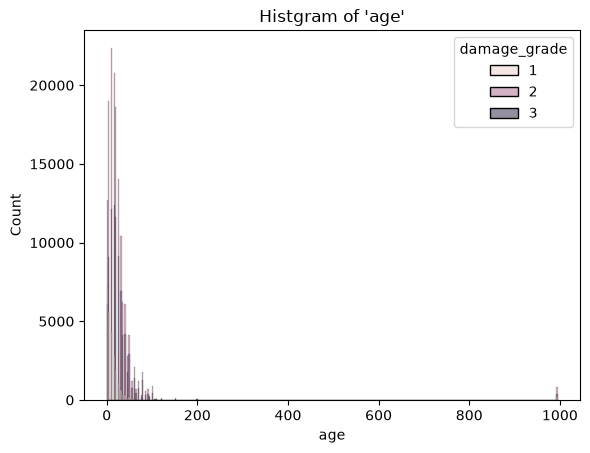

In [44]:
sns.histplot(data=df, x='age', hue='damage_grade', binwidth=3)
plt.title("Histgram of 'age'")
plt.show()

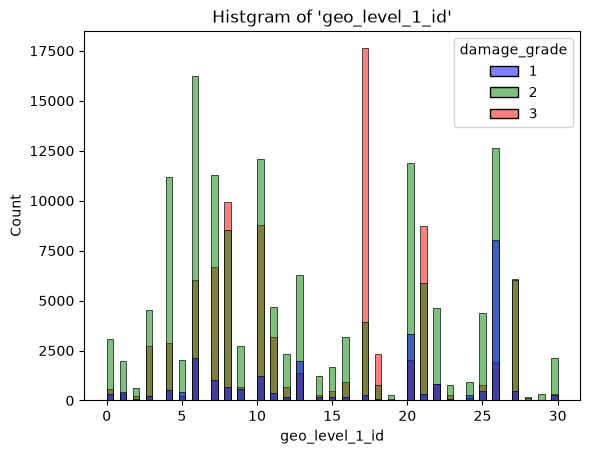

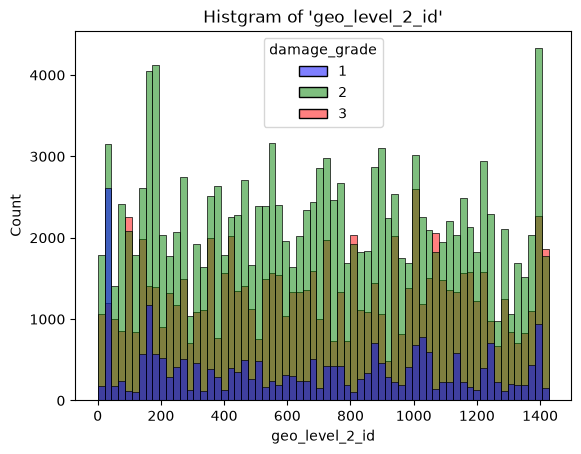

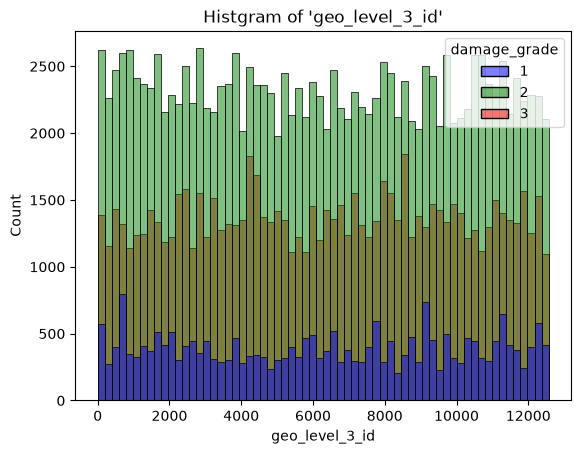

In [45]:
for col in id_col:
    sns.histplot(data=df, x=col, hue='damage_grade', palette=['blue', 'green', 'red'])
    plt.title(f"Histgram of '{col}'")
    plt.show()

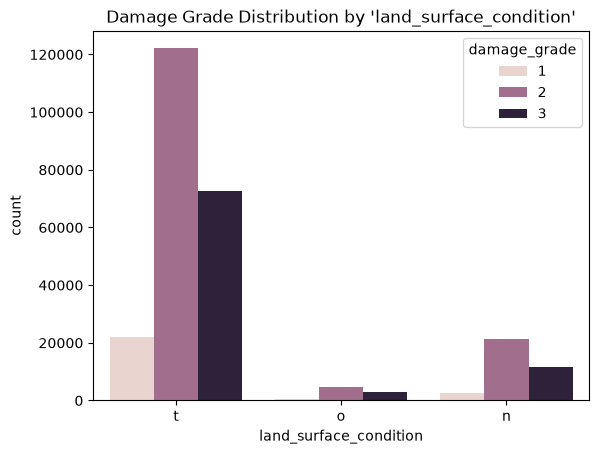

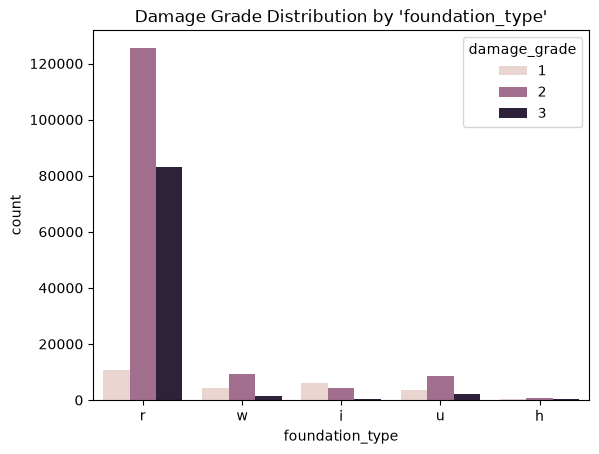

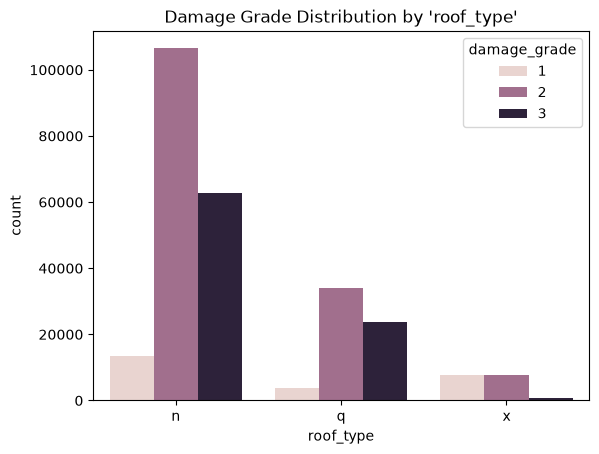

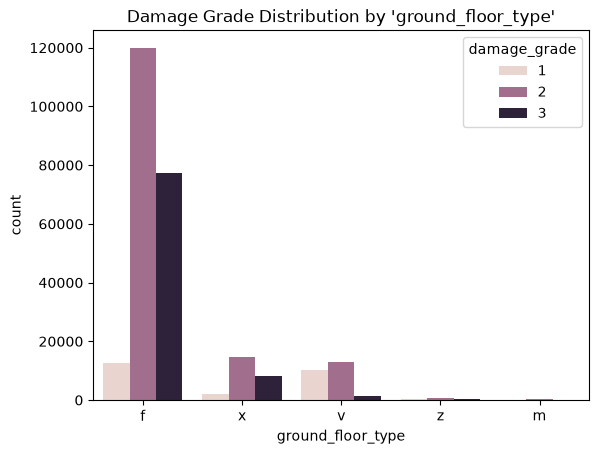

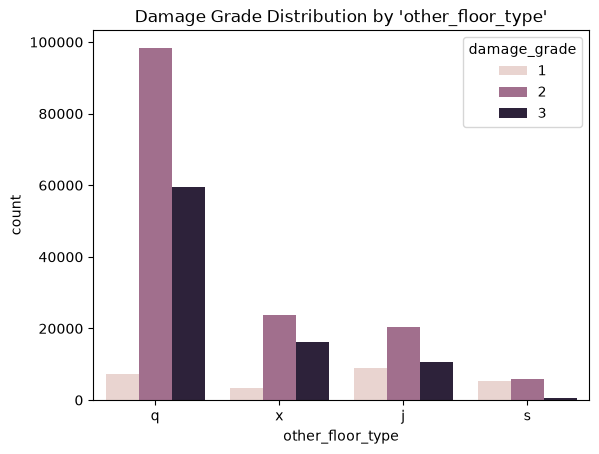

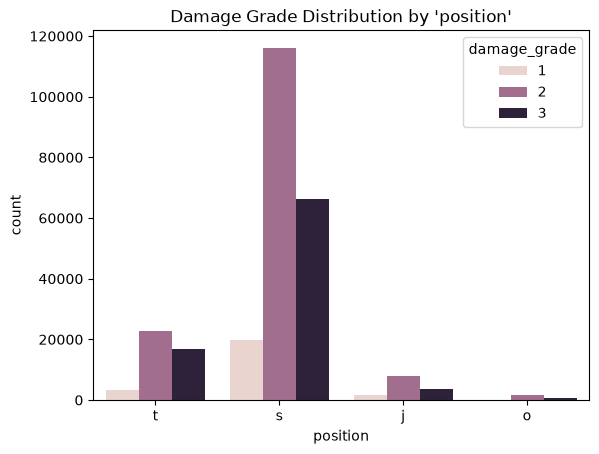

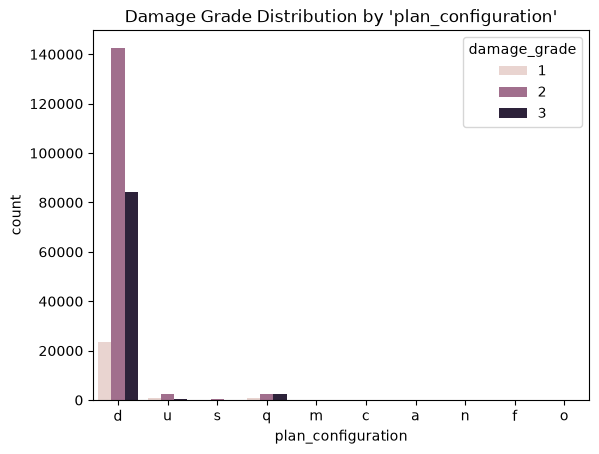

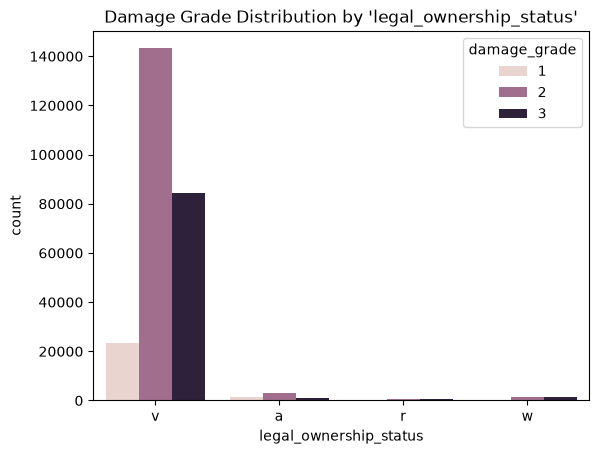

In [46]:
# Countplot

# Distribution of 'damage_grade' across different values of the each feature
for col in categorical_col:
    sns.countplot(x=col, hue='damage_grade', data=df)
    plt.title(f"Damage Grade Distribution by '{col}'")
    plt.show()

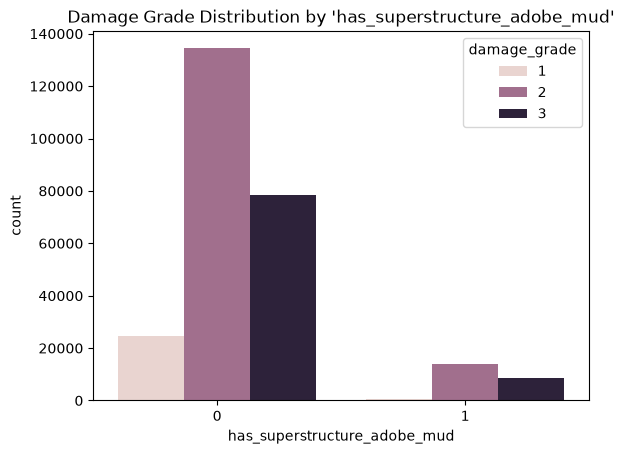

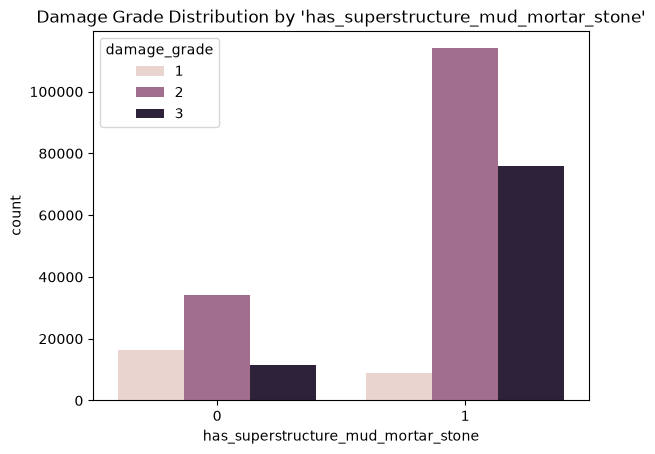

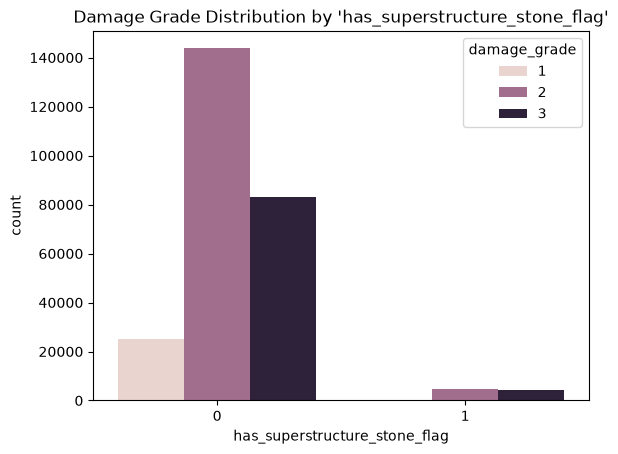

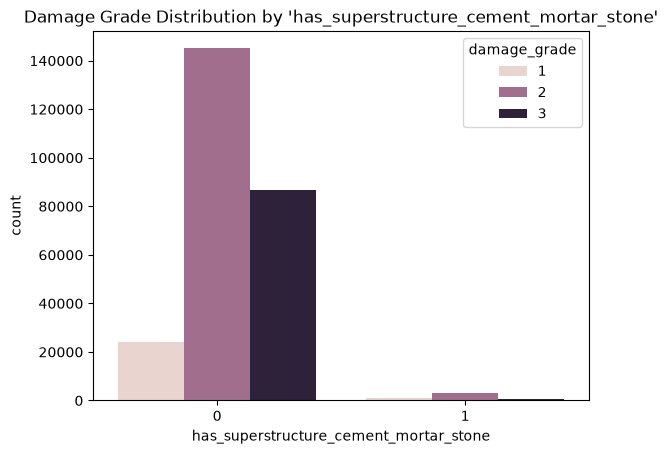

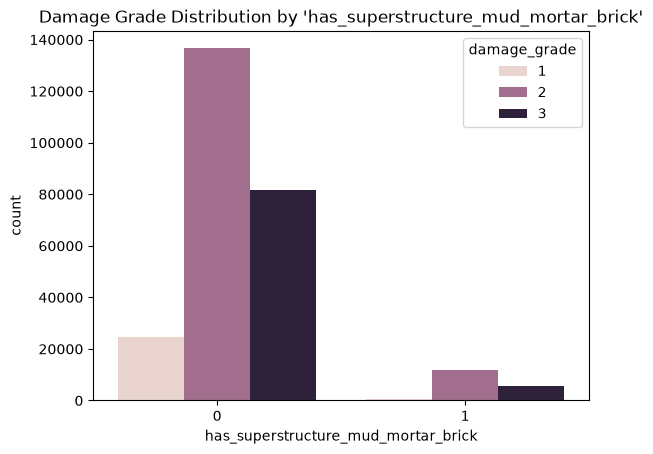

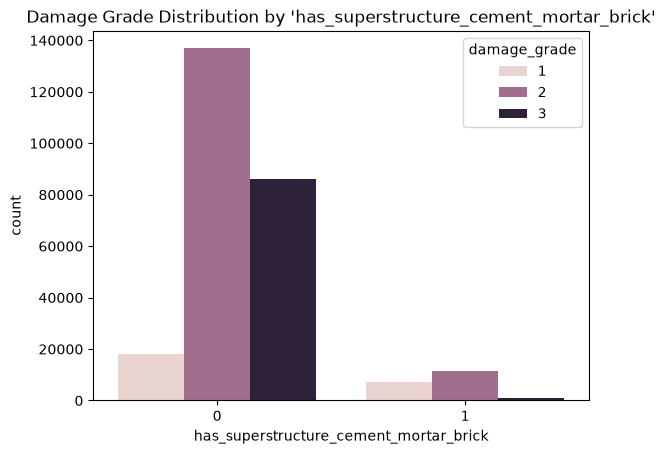

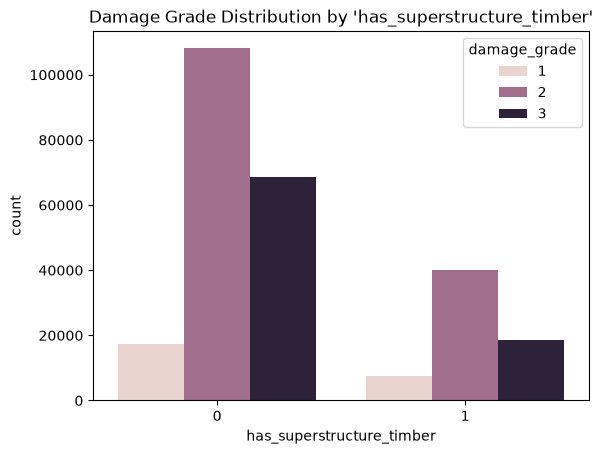

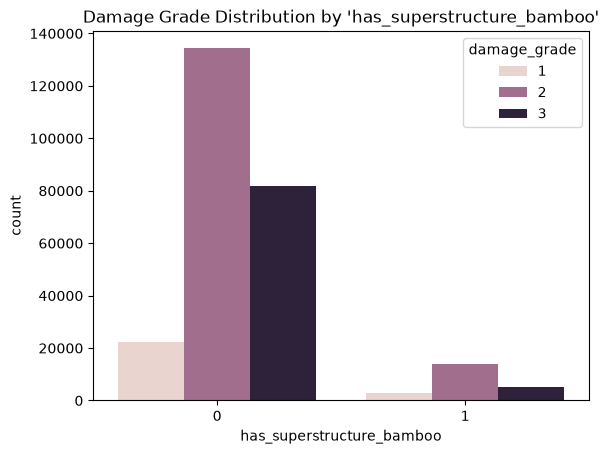

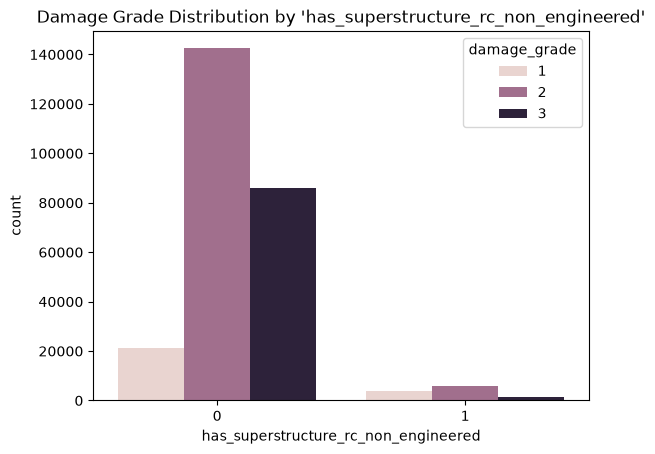

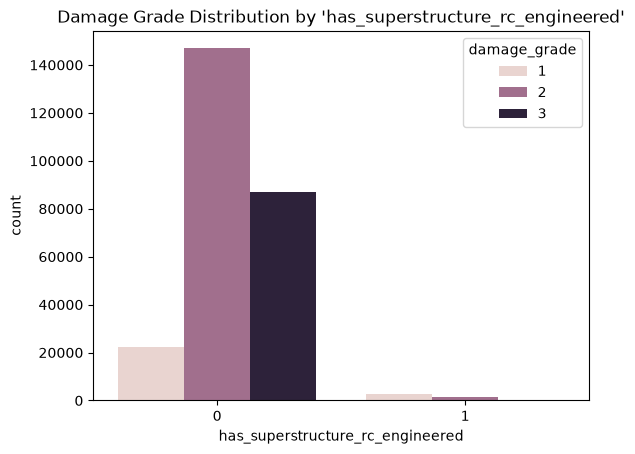

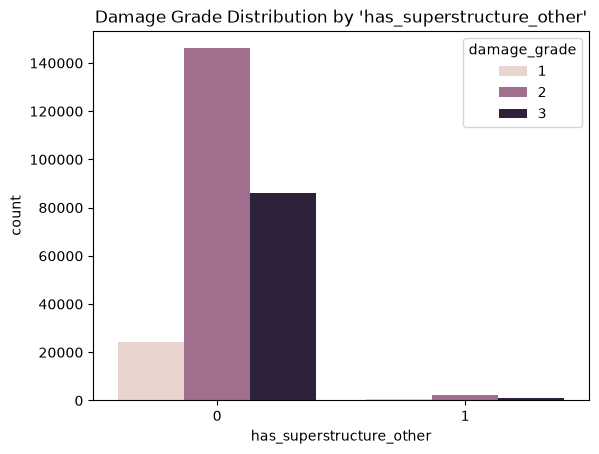

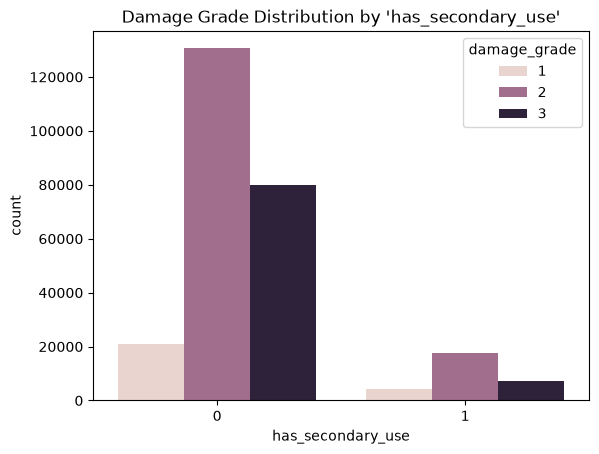

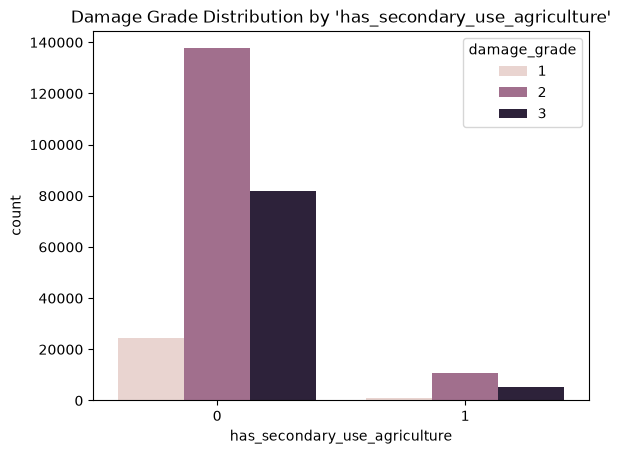

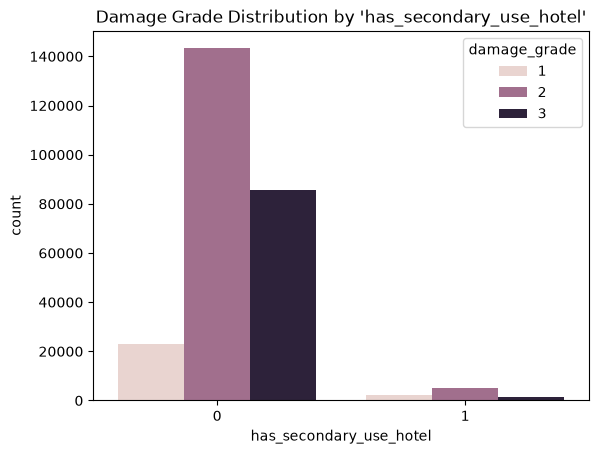

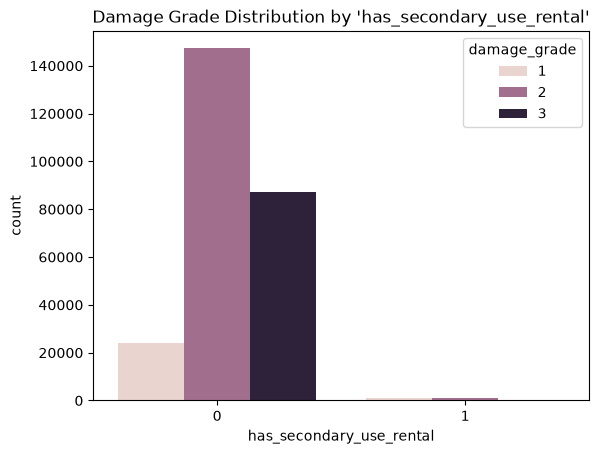

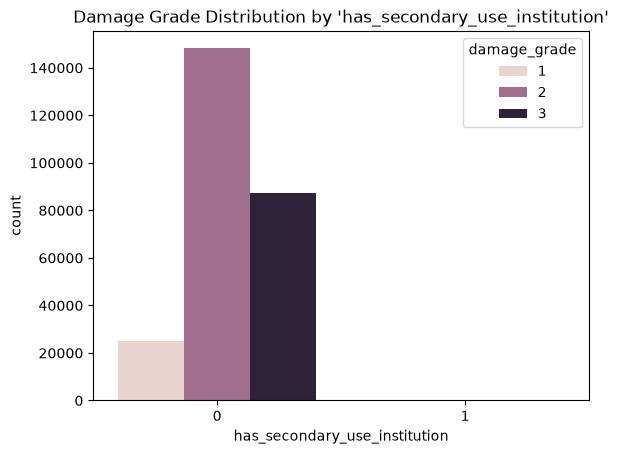

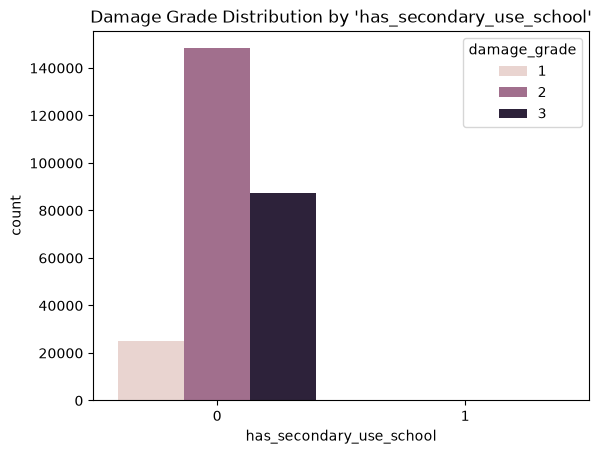

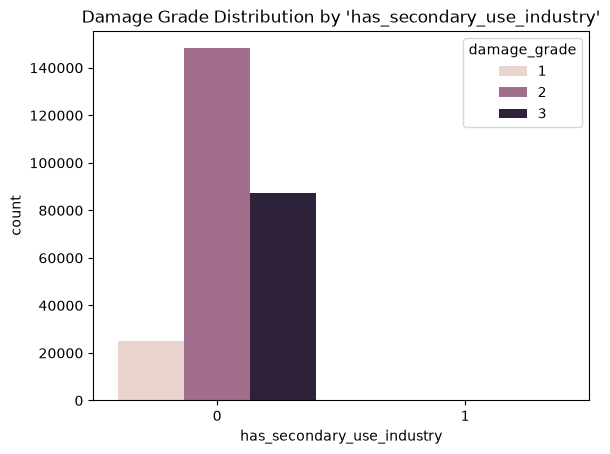

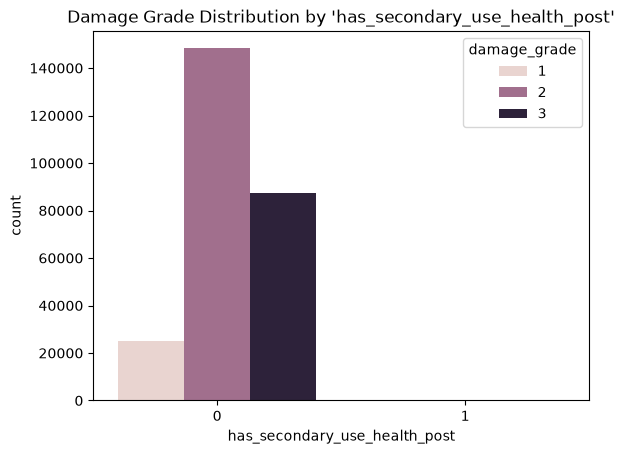

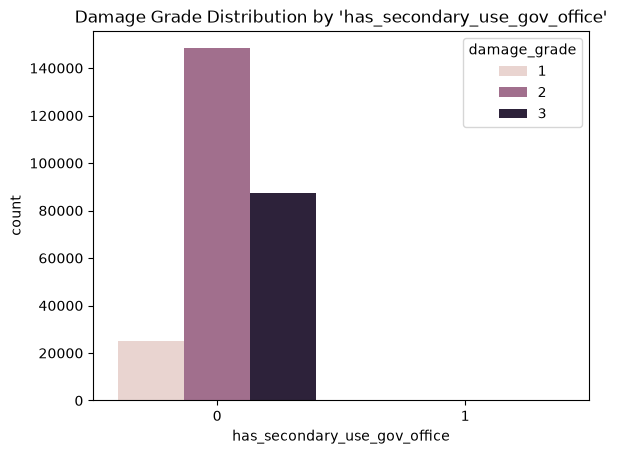

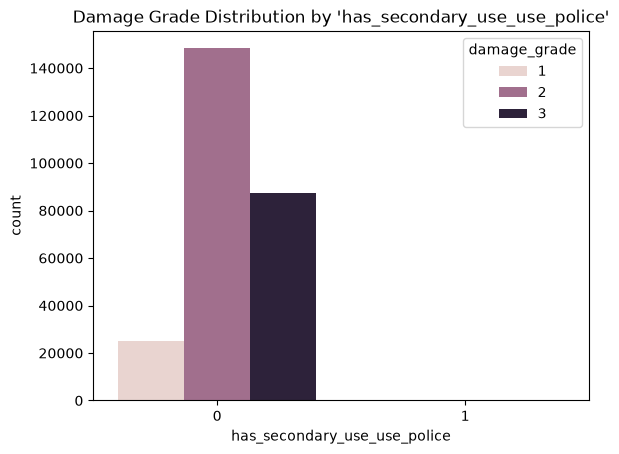

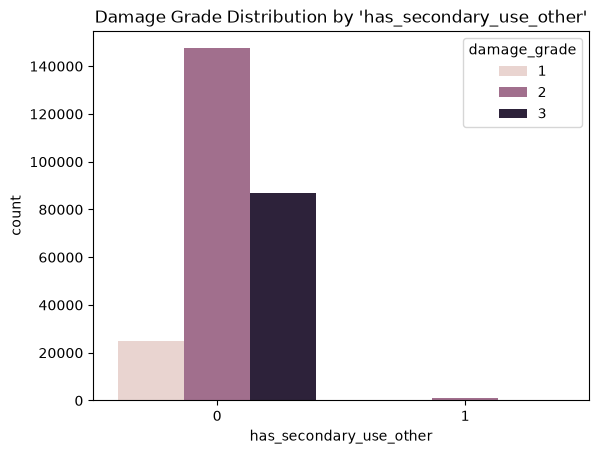

In [47]:
for col in binary_col:
    sns.countplot(x=col, hue='damage_grade', data=df)
    plt.title(f"Damage Grade Distribution by '{col}'")
    plt.show()

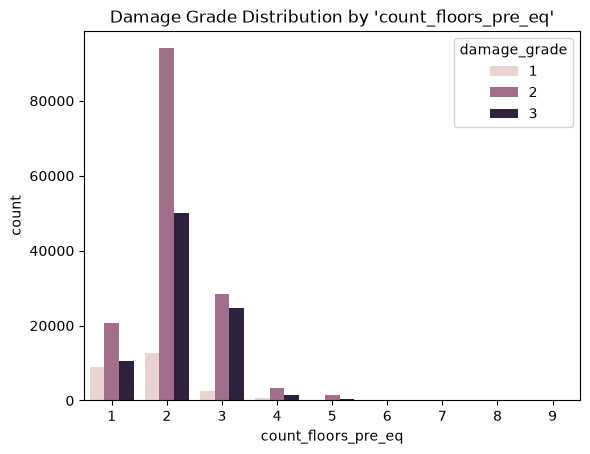

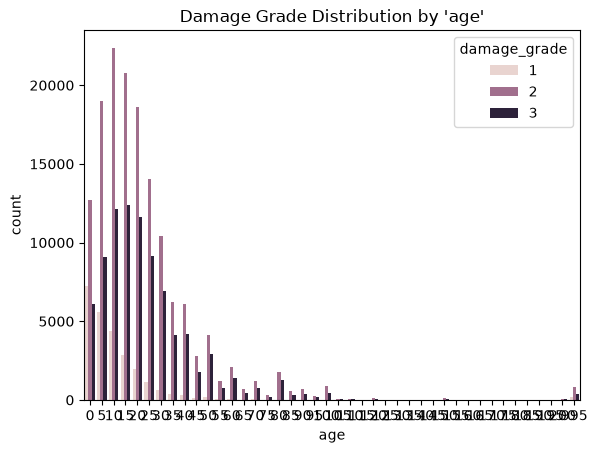

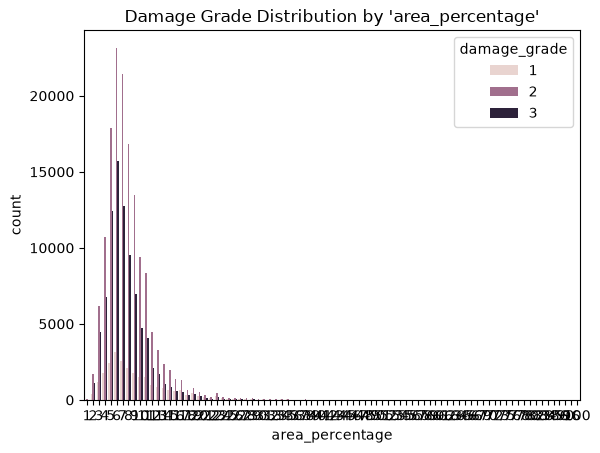

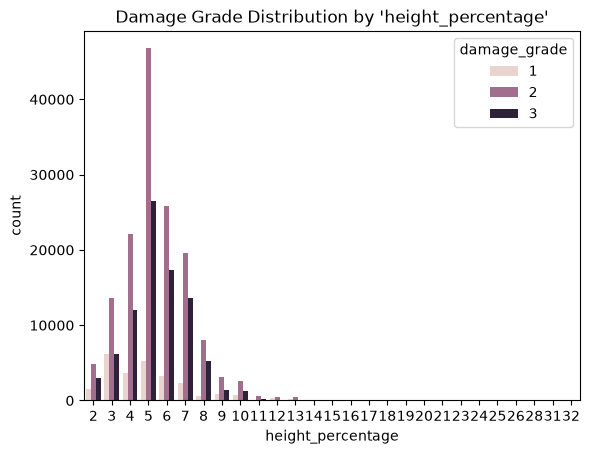

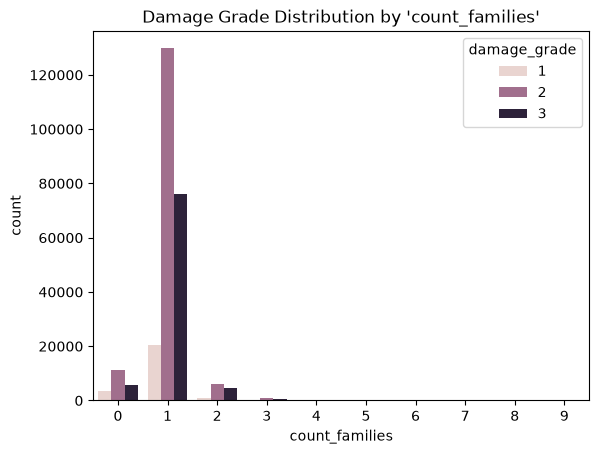

In [48]:
for col in int_col:
    sns.countplot(x=col, hue='damage_grade', data=df)
    plt.title(f"Damage Grade Distribution by '{col}'")
    plt.show()

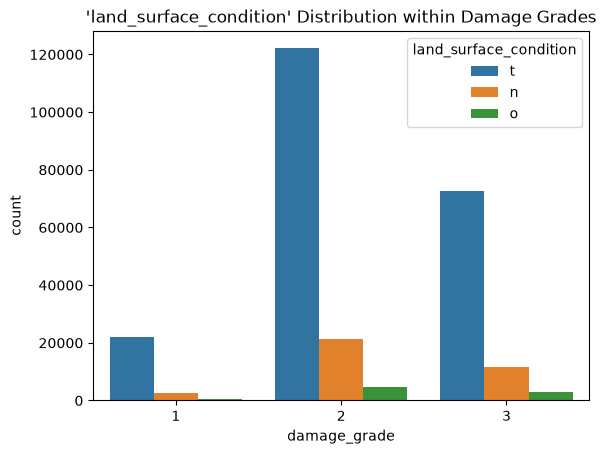

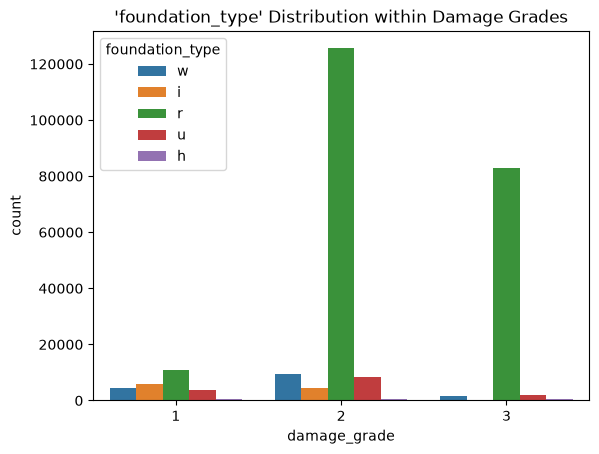

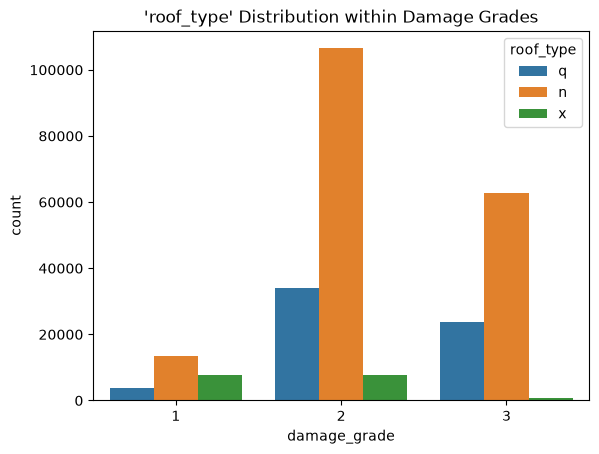

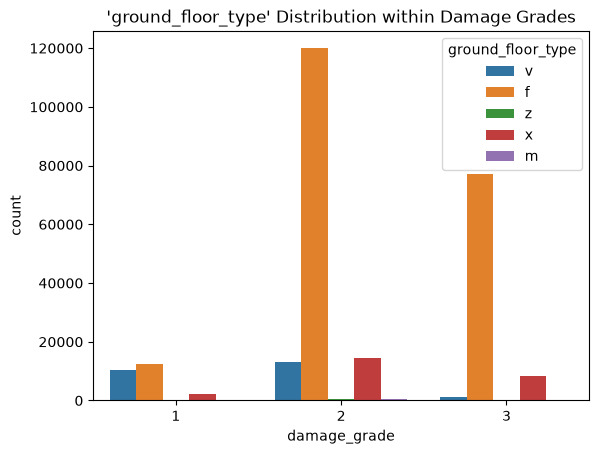

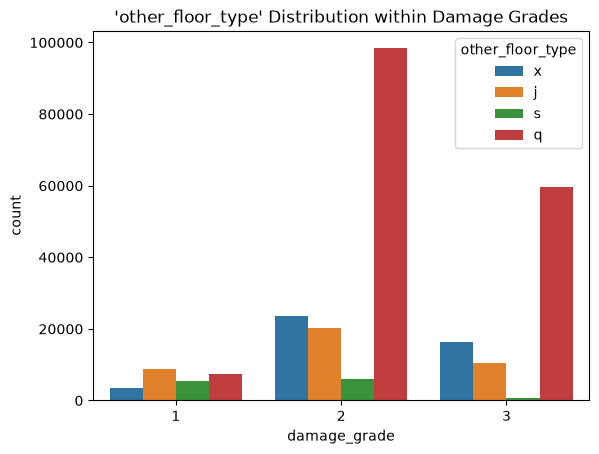

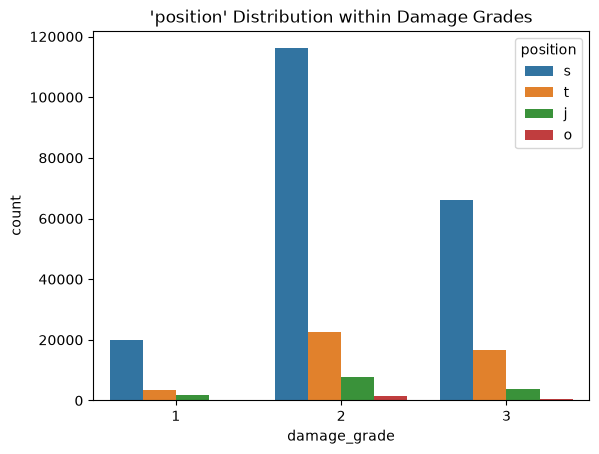

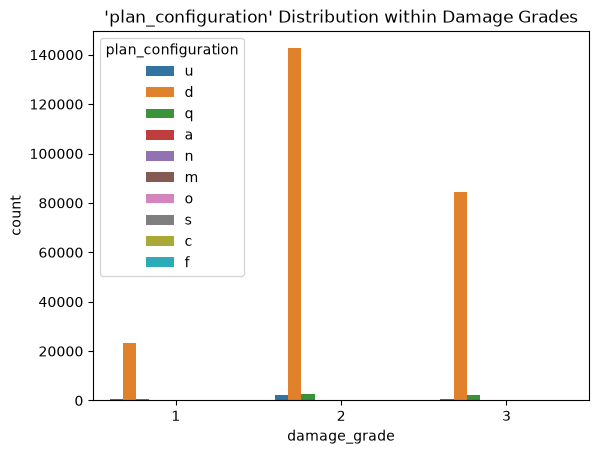

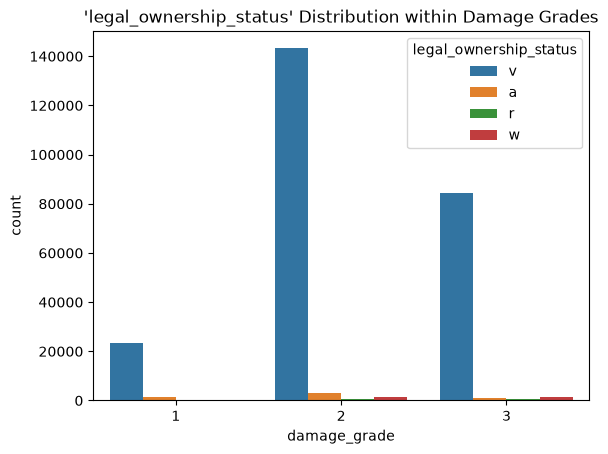

In [49]:
# Distribution of feature categories within each 'damage_grade'

for col in categorical_col:
    sns.countplot(x='damage_grade', hue=col, data=df)
    plt.title(f"'{col}' Distribution within Damage Grades")
    plt.show()

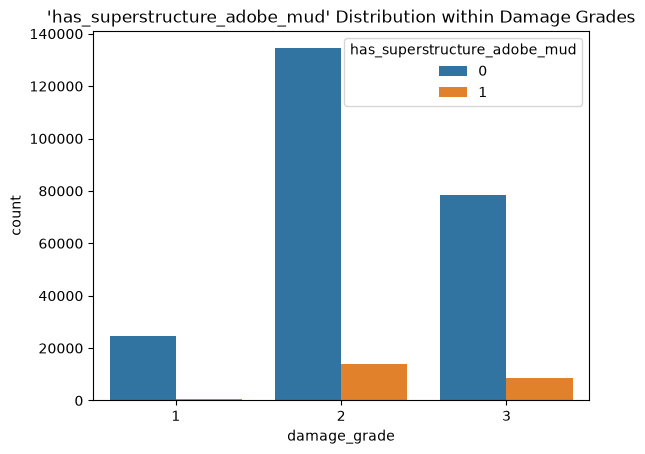

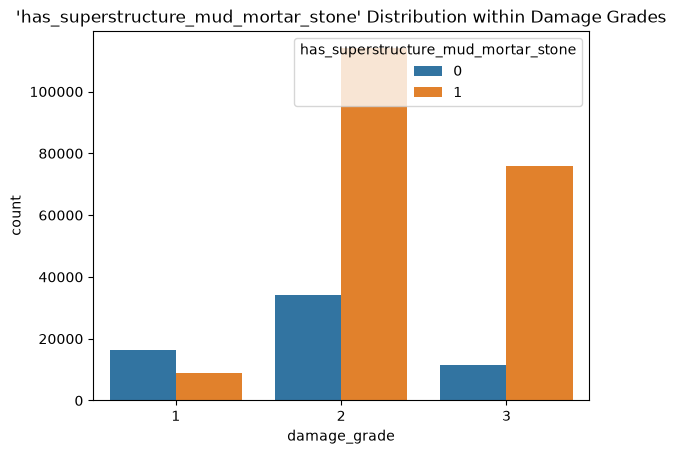

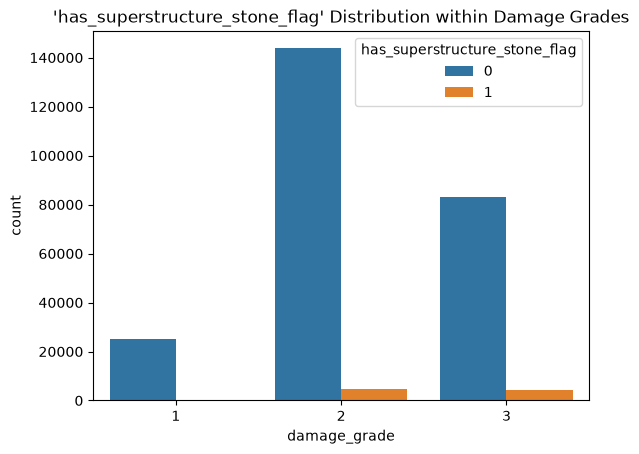

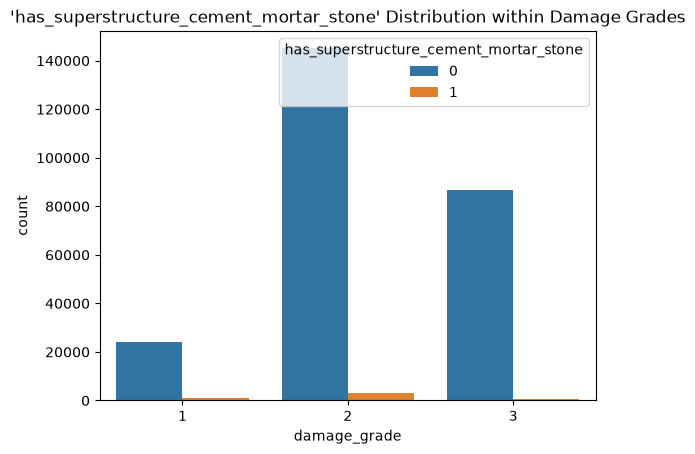

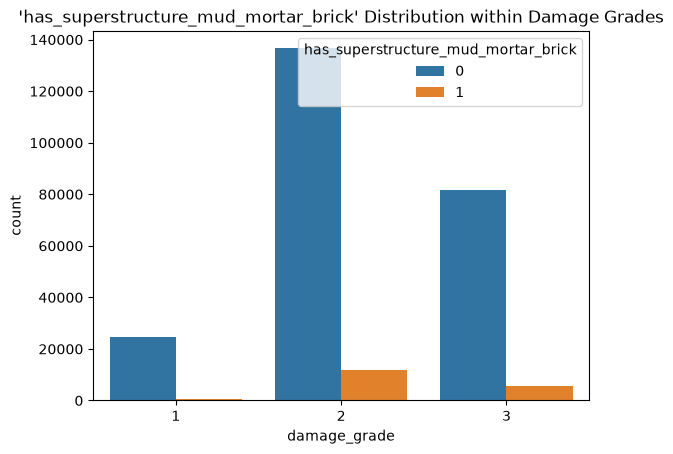

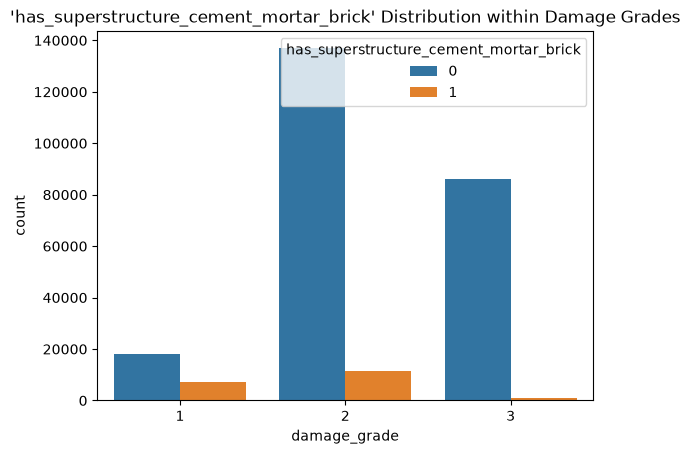

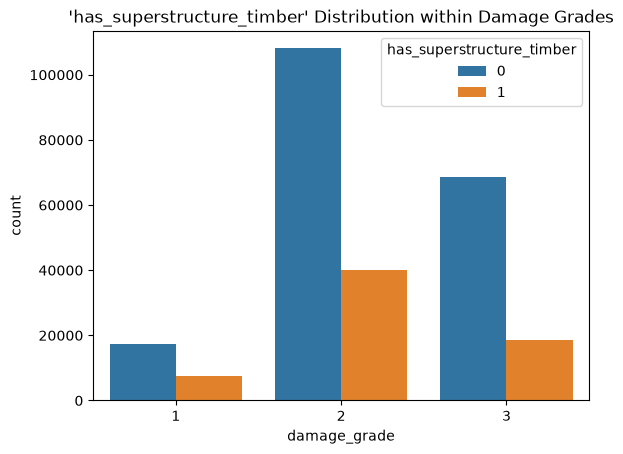

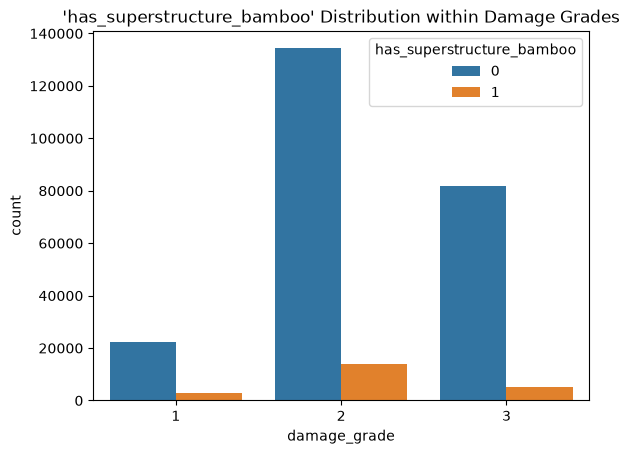

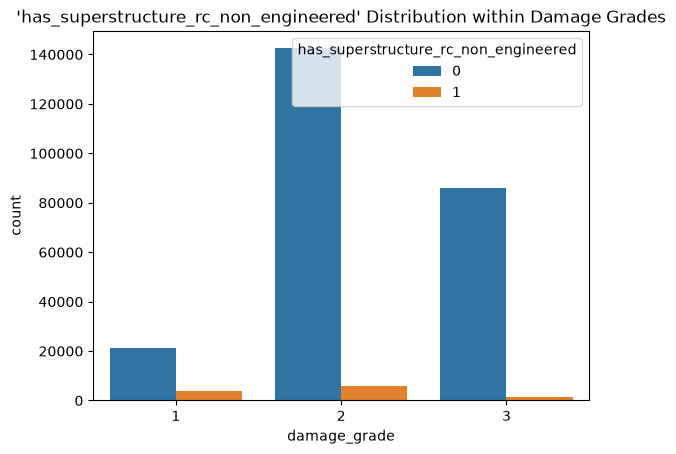

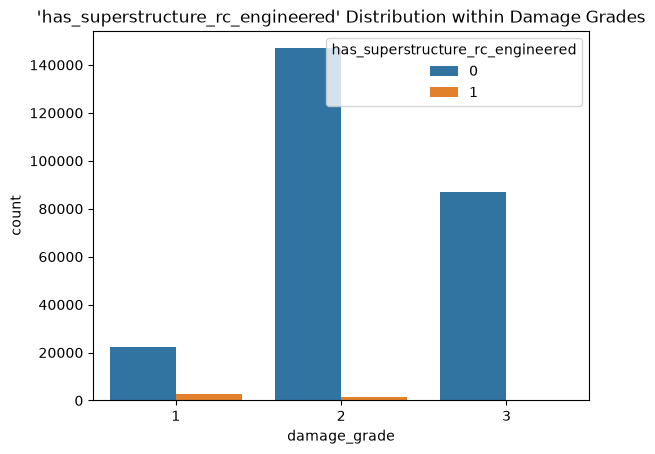

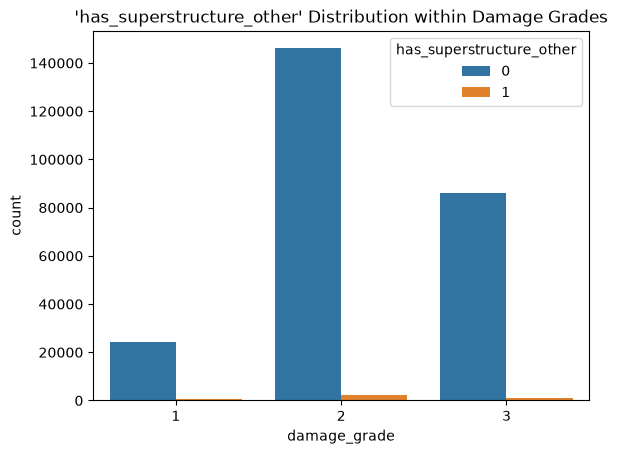

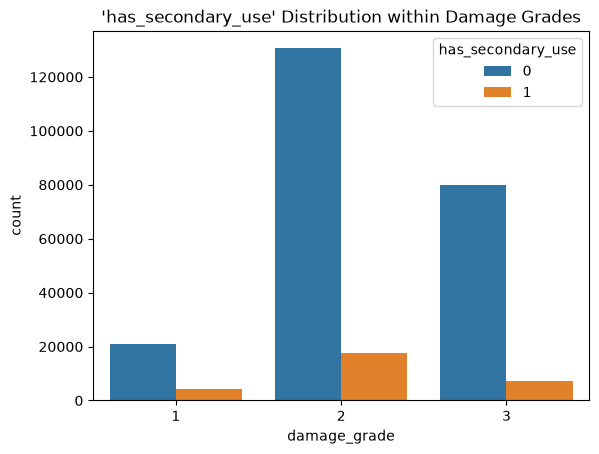

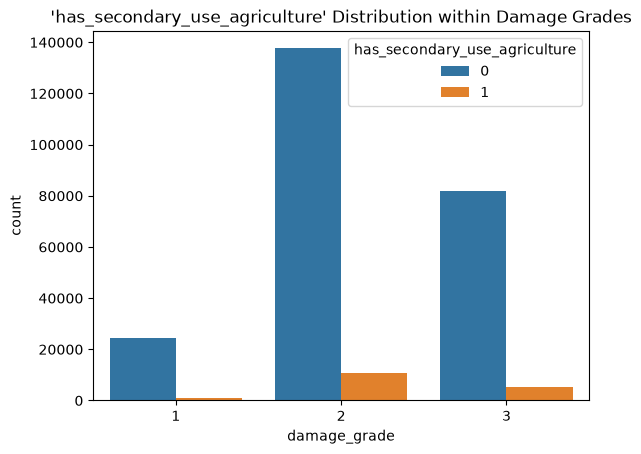

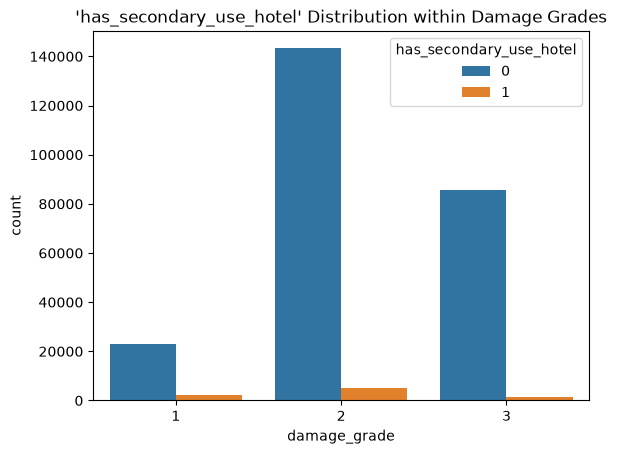

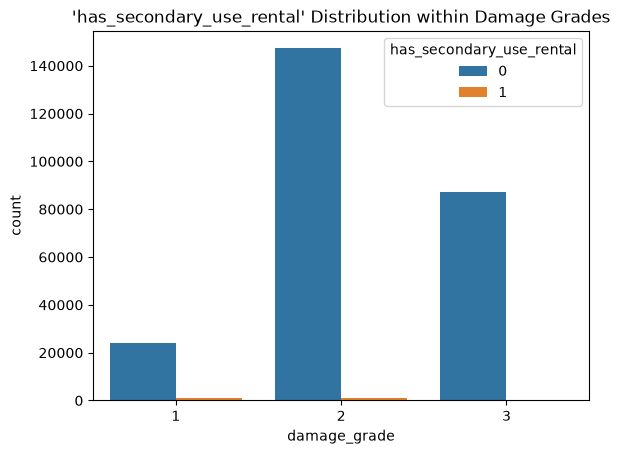

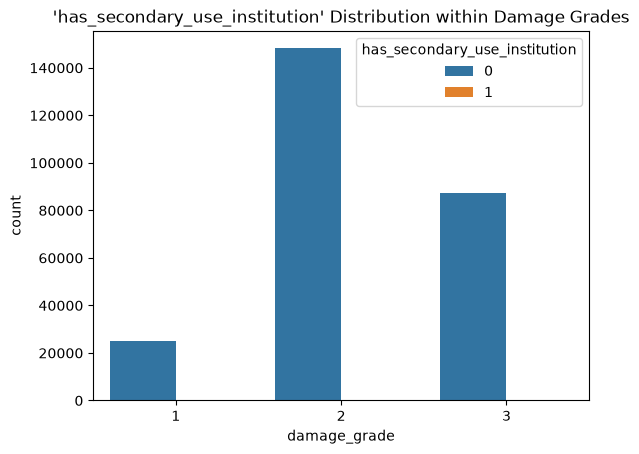

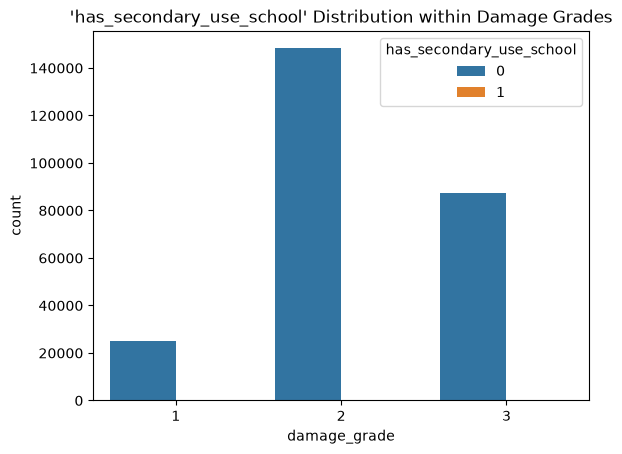

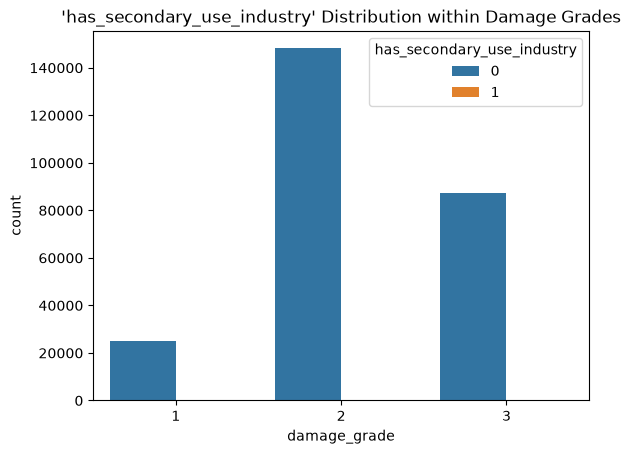

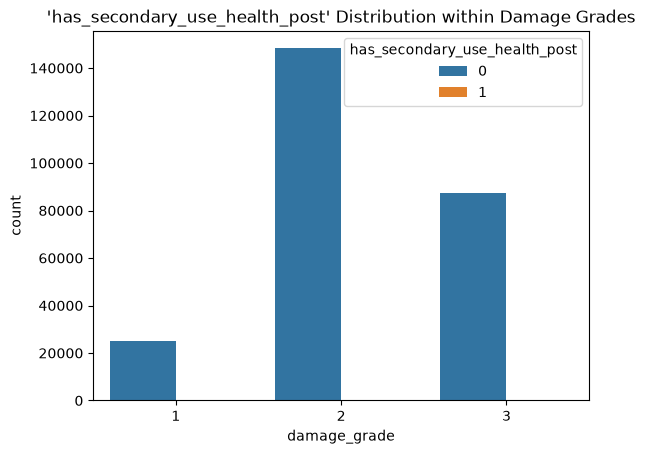

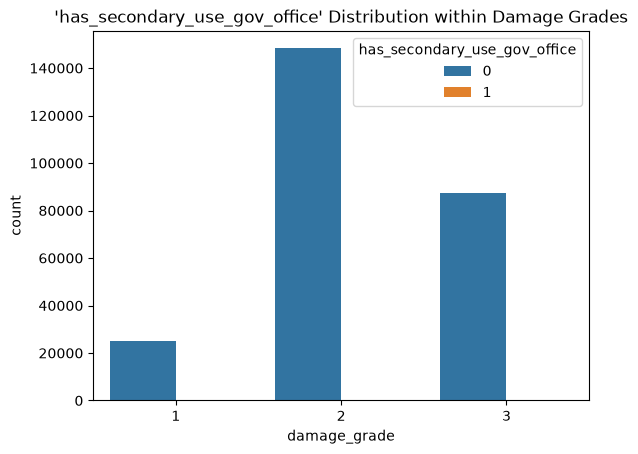

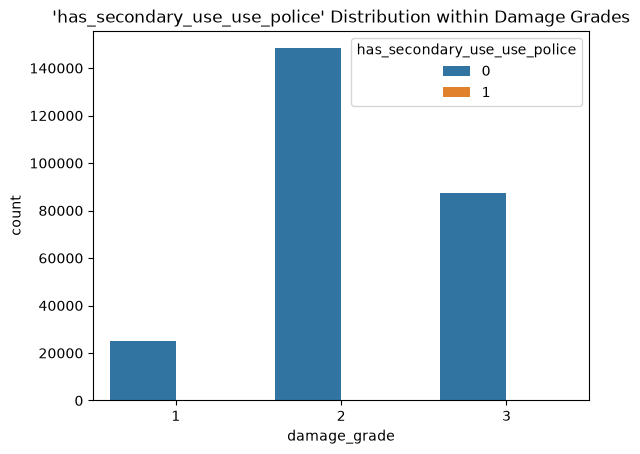

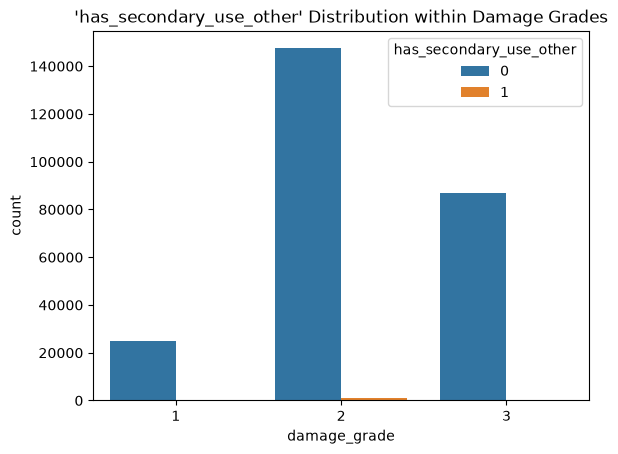

In [50]:
for col in binary_col:
    sns.countplot(x='damage_grade', hue=col, data=df)
    plt.title(f"'{col}' Distribution within Damage Grades")
    plt.show()

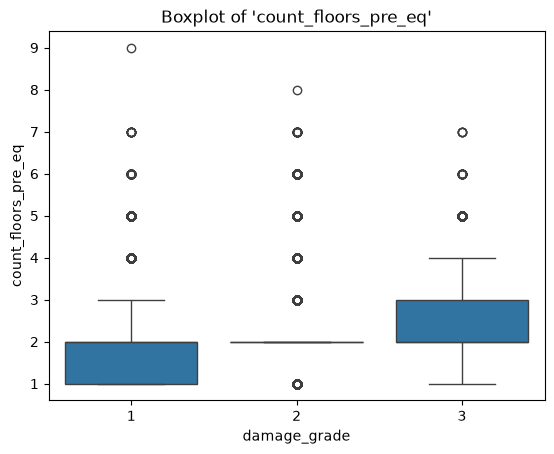

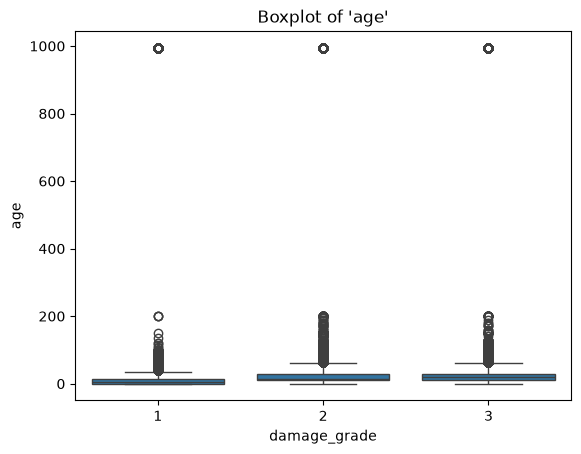

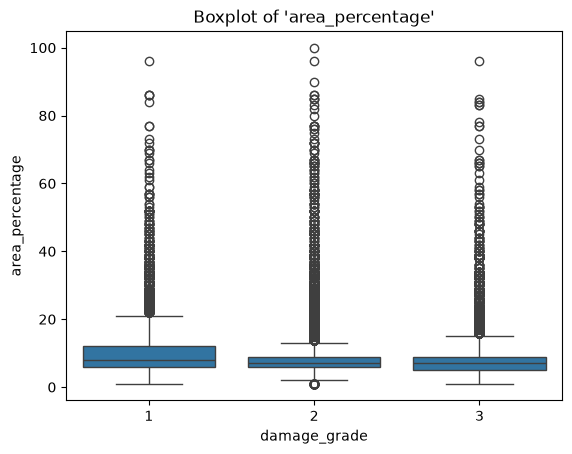

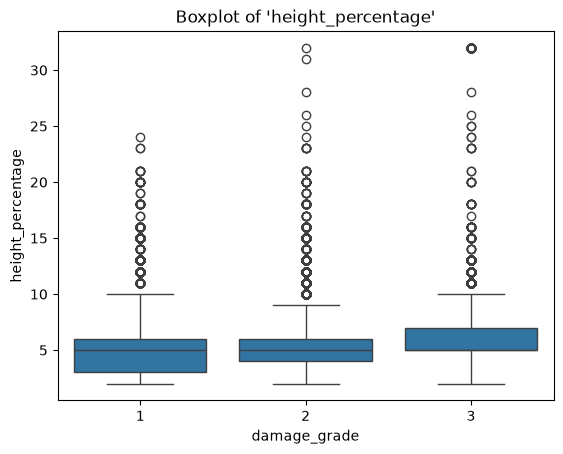

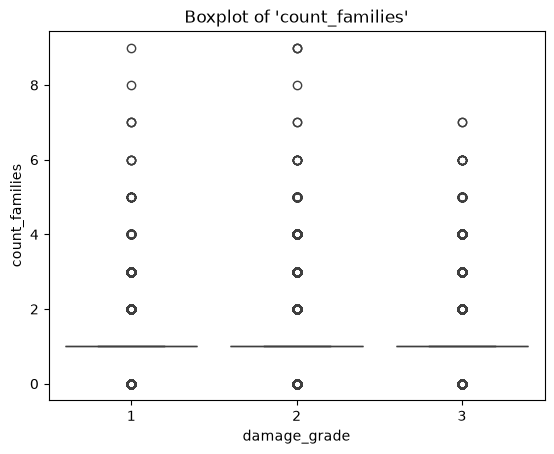

In [51]:
# Boxplot

for col in int_col:
    sns.boxplot(data=df, x='damage_grade', y=col)
    plt.title(f"Boxplot of '{col}'")
    plt.show()

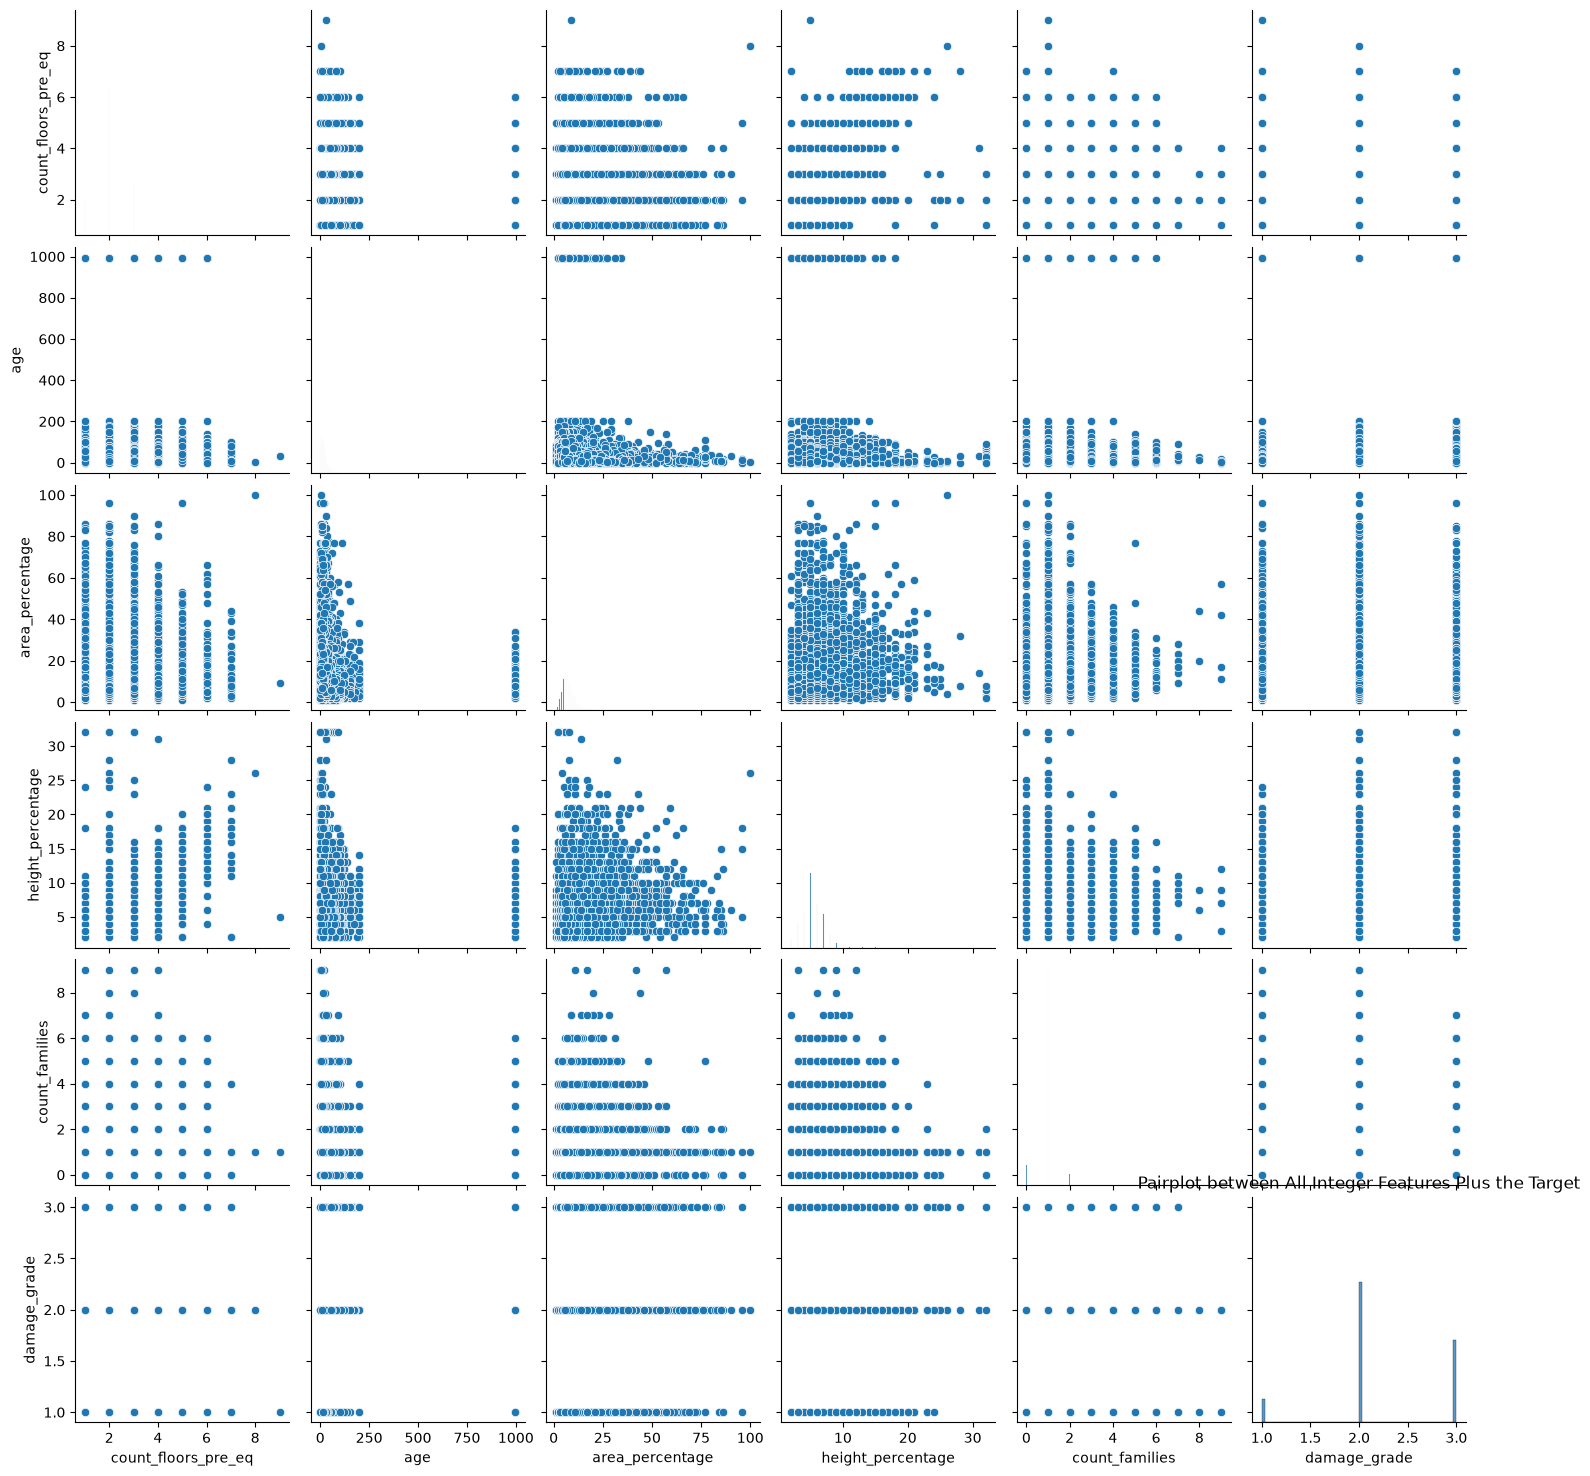

In [52]:
# Pairplot

sns.pairplot(df, vars=int_col + ['damage_grade'])
plt.title('Pairplot between All Integer Features Plus the Target')
plt.show()

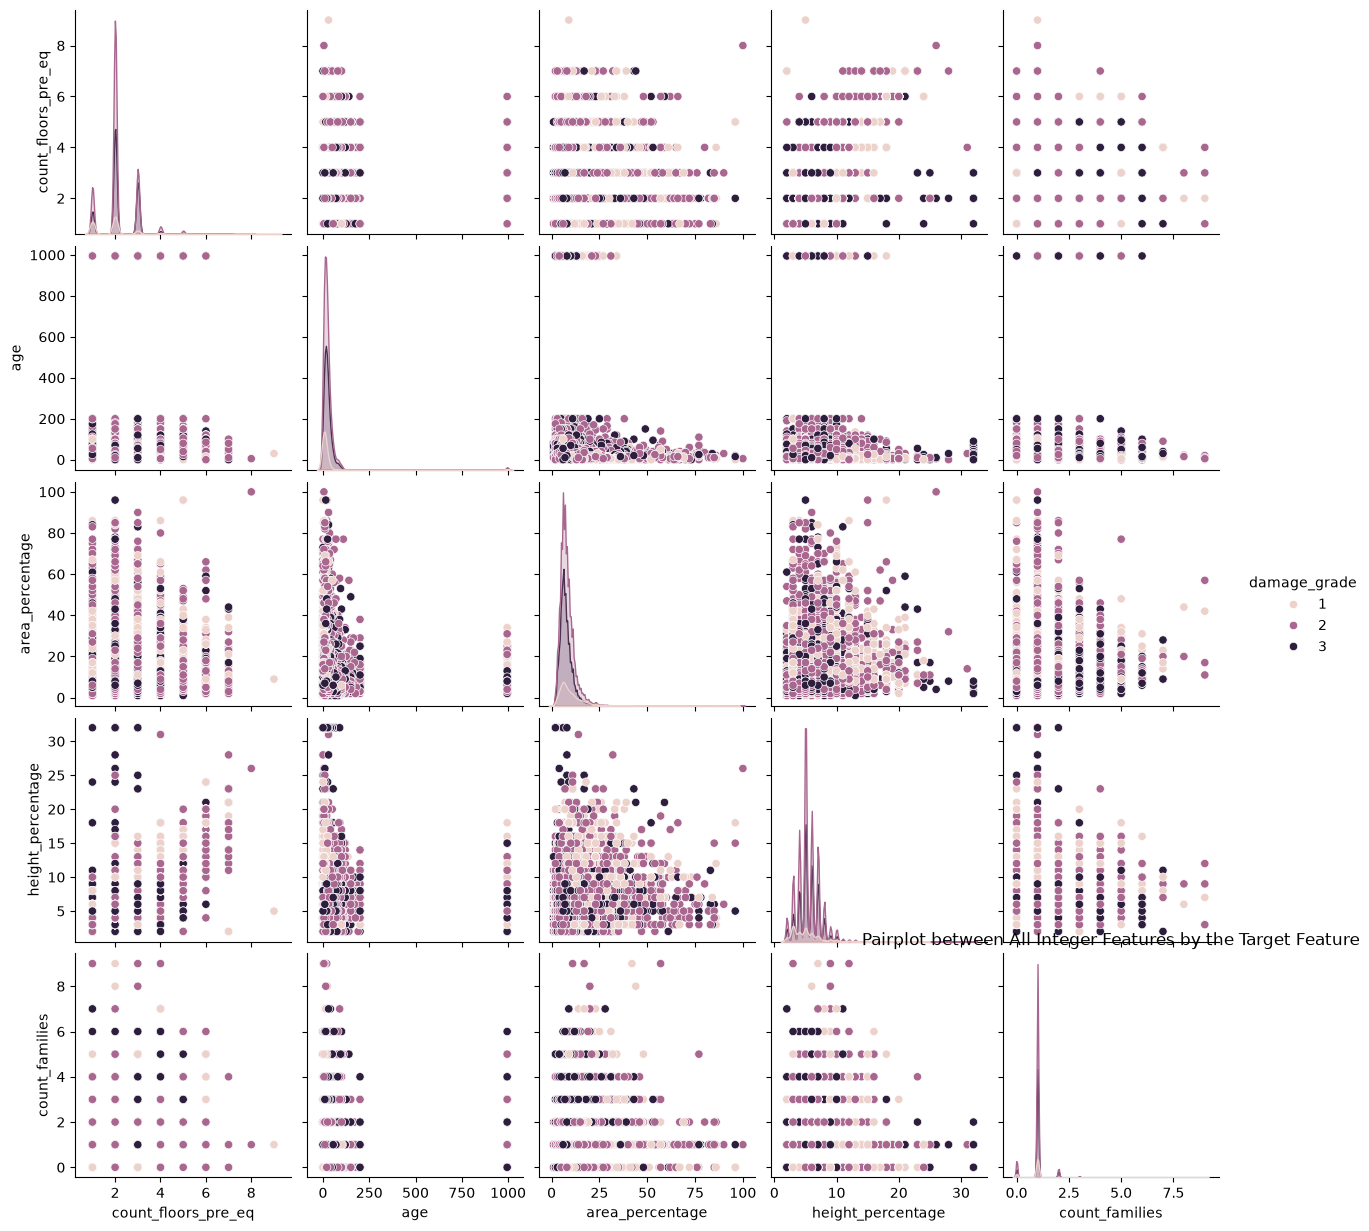

In [53]:
sns.pairplot(df, vars=int_col, hue='damage_grade')
plt.title('Pairplot between All Integer Features by the Target Feature')
plt.show()

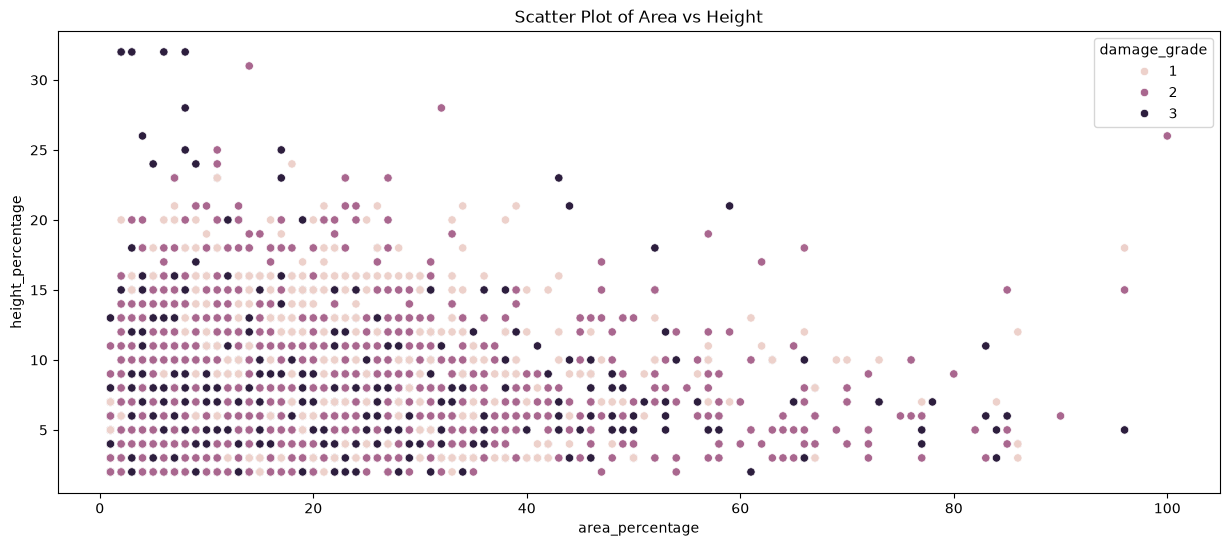

In [54]:
# Scatterplot of 'area_percentage' and 'height_percentage'

plt.figure(figsize=(15, 6))
sns.scatterplot(x='area_percentage', y='height_percentage', data=df, hue = 'damage_grade')
plt.title('Scatter Plot of Area vs Height')
plt.show()

### Correlation

In [55]:
# Correlation coefficients between all numerical features

corr = df.corr(numeric_only = True).drop(['building_id'], axis=0).drop(['building_id'], axis=1)
corr

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
geo_level_1_id,1.000000,-0.061405,0.002718,-0.089364,-0.003908,0.071158,-0.063474,-0.018245,-0.152038,0.007677,0.023656,-0.028854,0.134121,0.144985,0.074169,0.016454,0.015767,0.022670,0.035108,-0.010428,-0.019786,0.001911,0.023523,0.003700,0.002977,0.002655,-0.002303,0.001060,0.000523,-0.017992,-0.072347
geo_level_2_id,-0.061405,1.000000,0.000921,0.047730,0.012594,-0.049443,0.035516,0.015833,0.076491,-0.008743,-0.009122,0.014246,-0.079875,-0.023927,-0.032588,-0.038173,-0.036074,-0.020144,-0.012439,-0.001519,0.017522,-0.008439,-0.030704,-0.004840,-0.004856,0.000687,-0.000757,-0.000152,0.001926,-0.013068,0.043161
geo_level_3_id,0.002718,0.000921,1.000000,-0.021646,-0.006385,-0.005643,-0.024507,-0.015732,0.026294,0.019579,0.005966,-0.023278,-0.005116,-0.003916,0.006143,0.002265,-0.012420,-0.010604,-0.002479,0.007375,0.015995,-0.002001,-0.007356,-0.007058,-0.004373,-0.000862,-0.002632,-0.000943,0.000269,-0.002463,0.007932
count_floors_pre_eq,-0.089364,0.047730,-0.021646,1.000000,0.086668,0.101071,0.772734,0.174852,-0.027116,-0.041058,-0.011329,0.257279,-0.085821,-0.056637,-0.070487,0.007448,0.049000,-0.029888,0.086586,0.052125,-0.005294,0.077120,0.035425,0.016384,0.008833,-0.002611,0.006786,0.009639,0.003939,-0.002073,0.122308
age,-0.003908,0.012594,-0.006385,0.086668,1.000000,-0.004323,0.061074,0.068032,0.001321,0.009129,-0.012128,0.079525,-0.036992,0.005855,-0.008374,-0.025431,-0.025552,-0.001520,0.005309,-0.008788,-0.002194,-0.010021,0.001193,-0.004189,-0.003514,-0.003658,-0.002169,-0.001764,-0.001195,-0.004534,0.029273
area_percentage,0.071158,-0.049443,-0.005643,0.101071,-0.004323,1.000000,0.196645,0.026287,-0.225541,-0.000473,0.073701,0.053362,0.210800,-0.053965,-0.031641,0.185047,0.224647,0.007928,0.088630,0.122401,-0.016478,0.159885,0.105983,0.052212,0.050164,0.019421,0.015109,0.015290,0.004983,0.013111,-0.125221
height_percentage,-0.063474,0.035516,-0.024507,0.772734,0.061074,0.196645,1.000000,0.149725,-0.106573,-0.020260,0.012960,0.209098,0.001698,-0.052402,-0.063342,0.086228,0.129698,-0.019266,0.064316,0.091780,-0.005390,0.123551,0.068909,0.031366,0.020032,0.001946,0.011192,0.014660,0.004048,0.005397,0.048130
has_superstructure_adobe_mud,-0.018245,0.015833,-0.015732,0.174852,0.068032,0.026287,0.149725,1.000000,-0.306861,0.006962,-0.014554,0.314979,-0.037549,0.011694,0.011528,-0.036830,-0.036782,0.057545,0.033068,-0.013300,-0.003917,-0.012642,-0.003935,-0.004281,-0.002369,0.001762,-0.003292,-0.002648,-0.001493,-0.010074,0.055314
has_superstructure_mud_mortar_stone,-0.152038,0.076491,0.026294,-0.027116,0.001321,-0.225541,-0.106573,-0.306861,1.000000,-0.034046,-0.104288,-0.376208,-0.470715,-0.040177,-0.054657,-0.222366,-0.224509,-0.041705,0.001576,-0.087520,0.058261,-0.159532,-0.117948,-0.036064,-0.023070,-0.025507,-0.008763,-0.011904,-0.003380,0.005628,0.291325
has_superstructure_stone_flag,0.007677,-0.008743,0.019579,-0.041058,0.009129,-0.000473,-0.020260,0.006962,-0.034046,1.000000,0.037307,-0.033348,-0.043729,0.125311,0.078466,0.008448,-0.021406,0.065732,0.004564,-0.001738,0.010563,-0.008868,-0.011632,-0.000971,-0.001362,-0.004240,-0.002586,0.002959,0.000472,0.002127,0.066039


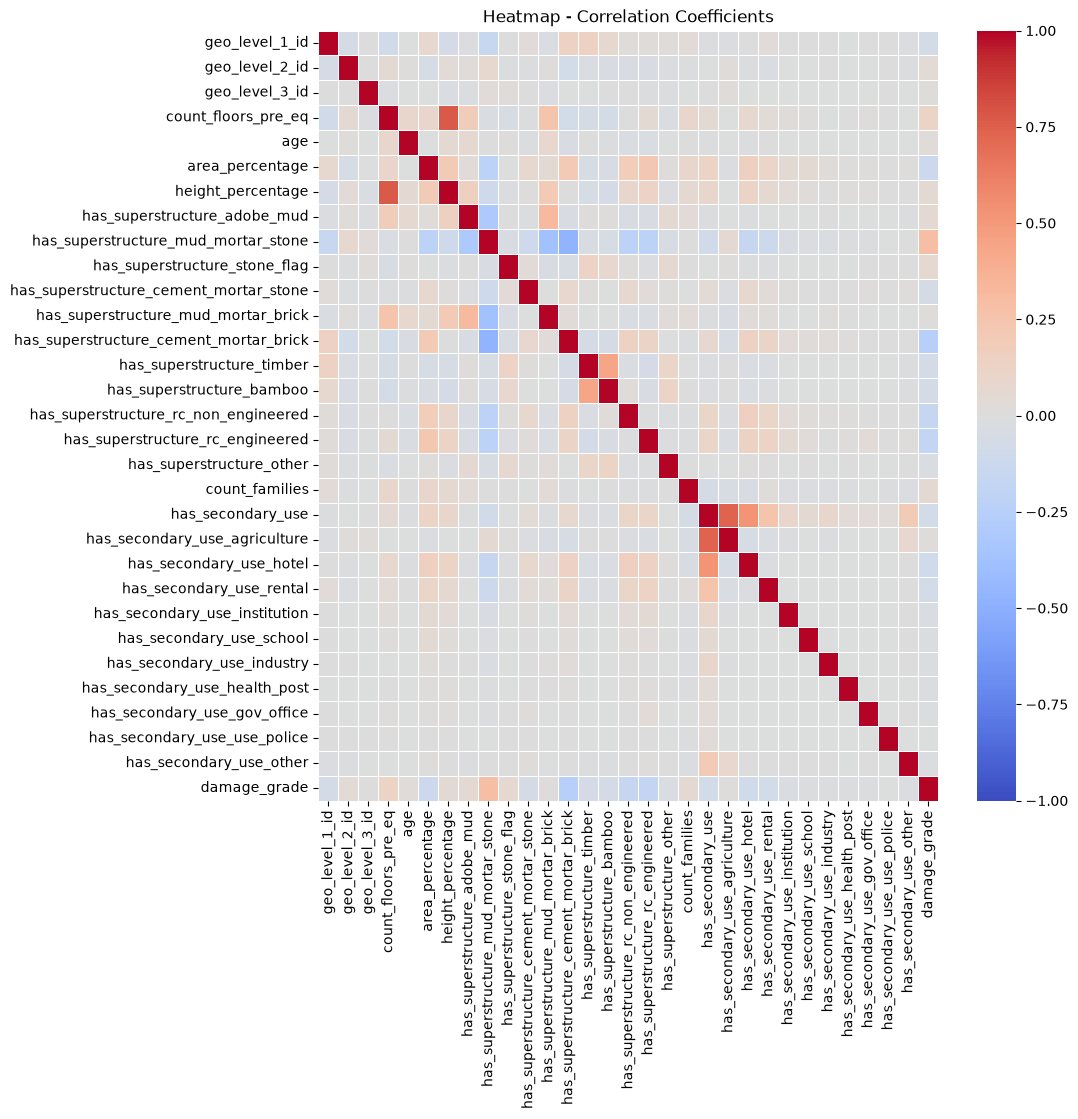

In [56]:
# Correlation heatmap

plt.figure(figsize=(10, 10))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap - Correlation Coefficients')
# plt.savefig('plots/heatmap_corr.png')
plt.show()

In [57]:
# Correlation coefficient between numerical features and the target 'damage_grade'

df.corr(numeric_only = True).damage_grade.drop(['building_id','damage_grade']).sort_values(ascending=False).reset_index()

,index,damage_grade
0,has_superstructure_mud_mortar_stone,0.291325
1,count_floors_pre_eq,0.122308
2,has_superstructure_stone_flag,0.066039
3,count_families,0.056151
4,has_superstructure_adobe_mud,0.055314
5,height_percentage,0.048130
6,geo_level_2_id,0.043161
7,age,0.029273
8,has_superstructure_mud_mortar_brick,0.014561
9,has_secondary_use_agriculture,0.011309


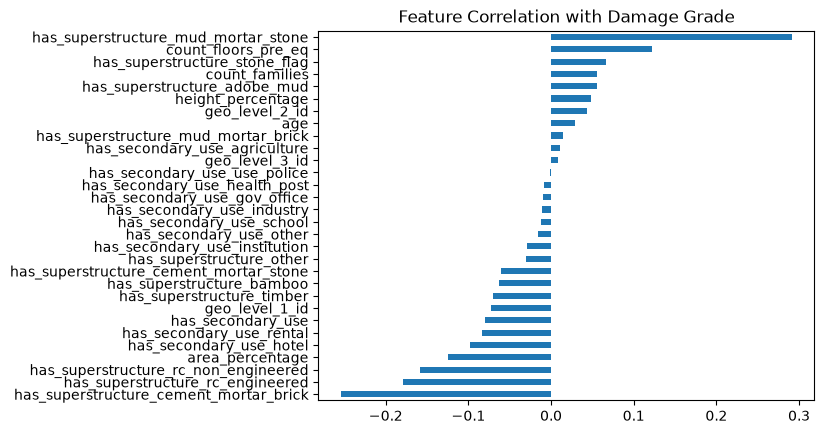

In [58]:
# Bar chart

df.corr(numeric_only = True).damage_grade.drop(['building_id','damage_grade']).sort_values().plot.barh()
plt.title('Feature Correlation with Damage Grade')
# plt.savefig('plots/barchart_corr.png')
plt.show()